In [126]:
import pandas as pd
import numpy as np
from scipy import stats
from matplotlib.patches import Ellipse, Patch
import matplotlib.pyplot as plt
from itertools import combinations
from IPython.display import Image, display, Markdown

In [127]:
# use the original df to find category scales
df = pd.read_pickle('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [128]:
df.columns.tolist()

['id',
 'time_window_start',
 'tweets_struct',
 'name',
 'username',
 'description',
 'location',
 'public_metrics.followers_count',
 'profile_image_url',
 'clean...pool',
 'is_empty_window',
 'window_weeks_to_election',
 'profile_image_description',
 'profile_image_main_info',
 'Model',
 'Belief_Raw',
 'Belief_Cleaned',
 'Demo_Raw',
 'Demo_Cleaned',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Category',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Explanation',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
 'Belief_opinion_on_the_number_of_immigrants_in_america_Speculation',
 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Category',
 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Explanation',
 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Symbol',
 'Belief_opinion_on_the_statement_immigrants_increase_crime_rates_Speculation',
 'Belief_opinion_on_the_statement_immigrants_take_jobs_away_fro

In [129]:
k = df[f"Belief_opinion_on_the_number_of_immigrants_in_america_Symbol_cat"].cat.categories.size
k

5

In [130]:
# use title from title mapper
title_mapper = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/title_mapper_with_titles.csv")
title_mapper.head()

,Feature,Question type,Question model,Match Dataset,Match ID,Match ID numeric (this is the V variable code for the ANES),Note from Yuyue,what to do,2024 Match Dataset,2024 Match ID,...,ANES/CCES,Our dataset,Warning,Target Quality,Some benchmark available,Add area-level R-D as pred. ?,Add area-level matched pre-2024 past score as pred. ?,Area-level pred. size,cleaned_feature,title
0,OPINION ON THE NUMBER OF IMMIGRANTS IN AMERICA,Likert,Ordinal,ANES2020,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,V202232,NaN,"Keep 1-5 as coded (1=increased a lot, 5=decrea...",ANES2024,POST: WHAT SHOULD IMMIGRATION LEVELS BE (IMMIG...,...,NaN,NaN,NaN,GOOD,True,1.0,1.0,2.0,Belief_opinion_on_the_number_of_immigrants_in_...,GSS -- LETIN1A / ANES2024 -- IMMIGPO_IMMLEVEL
1,OPINION ON THE STATEMENT << IMMIGRANTS INCREAS...,Likert,Ordinal,ANES2020,CSES5_IMMCRIME or GSS_IMMCRIMEGSS,V202420 or V202600,Here I chose V202420 because there are no actu...,Pick whichever beteween these two is less miss...,ANES2024,CSES6_IMMCRIME,...,drop neither agree or disagree respondents,NaN,NaN,GOOD,True,1.0,1.0,2.0,Belief_opinion_on_the_statement_immigrants_inc...,GSS -- IMMCRIME1 / ANES2024 -- CSES6_IMMCRIME
2,OPINION ON THE STATEMENT << IMMIGRANTS TAKE JO...,Likert,Ordinal,ANES2020,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,V202233,NaN,Reverse 1-4 so 4=extremely likely and 1=not at...,ANES2024,POST: HOW LIKELY IMMIGRATION WILL TAKE AWAY JO...,...,NaN,NaN,NaN,GOOD,True,1.0,1.0,2.0,Belief_opinion_on_the_statement_immigrants_tak...,GSS -- IMMJOBS1 / ANES2024 -- IMMIGPO_IMMJOBS
3,OPINION ON WHAT SHOULD BE DONE WITH ILLEGAL IM...,Likert,Ordinal,ANES2020,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,V201417,NaN,Collapse to 3 classes: 1=identified/deported; ...,ANES2024,PRE: U.S. GOVERNMENT POLICY TOWARD UNAUTHORIZE...,...,ANES Collapse to 3 classes: 1=identified/depor...,NaN,NaN,GOOD,True,1.0,1.0,2.0,Belief_opinion_on_what_should_be_done_with_ill...,GSS -- IMMFATE / ANES2024 -- IMMIG_IMMPOL
4,OPINION ON WHETHER DIVORCE IN THE USA SHOULD B...,Likert,Ordinal,ANES2020,POST: FEWER PROBLEMS IF THERE WAS MORE EMPHASI...,V202265,NaN,Reverse 1-5 so higher=more agreement with trad...,NaN,NaN,...,NaN,NaN,"GSS 2024 only exact match, no state-level matc...",NaN,True,1.0,0.0,1.0,Belief_opinion_on_whether_divorce_in_the_usa_s...,GSS -- DIVLAW


In [131]:
from pathlib import Path

base_path = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data')
belief_col = sorted([
  d.name for d in base_path.iterdir()
  if d.is_dir() and d.name.startswith('Belief_')
])
len(belief_col)
# belief_col = [ 'Belief_opinion_on_the_statement_the_use_of_puberty_blockers_and_other_genderaffirming_procedures_for_minors_should_be_allowed_Symbol',
#      'Belief_satisfaction_with_the_way_democracy_is_working_in_the_us_Symbol']


28

In [132]:
anes_window_label = '2024-08-11'

In [133]:
cces_window_label = '2024-10-06'

In [134]:
gss_window_label = '2024-04-07'

In [135]:
anes_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_anes_target_df.csv",)
anes_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
93852,Female,NaN,<50k,NaN,College,NaN,California,"[2024-10-20 , 2024-11-03)",NaN,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93853,Female,55+,50-100k,White,Non-college,Democratic,Minnesota,"[2024-09-22 , 2024-10-06)",2.0,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93854,Female,NaN,<50k,Non-white,Non-college,NaN,Virginia,"[2024-10-06 , 2024-10-20)",NaN,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024
93855,Male,18-34,50-100k,Non-white,College,Democratic,New Jersey,"[2024-10-20 , 2024-11-03)",1.0,Belief_opinion_on_the_large_reduction_in_the_p...,ANES2024


In [136]:
cces_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_cces_target_df.csv",)
cces_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Female,35-54,<50k,Non-white,Non-college,Democratic,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
1,Male,55+,100k+,Non-white,College,Democratic,New York,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
2,Female,55+,<50k,White,College,Other,Pennsylvania,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
3,Female,18-34,<50k,White,Non-college,StayHome,California,"[2024-09-22 , 2024-10-06)",1.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
4,Female,55+,<50k,White,Non-college,Republican,Montana,"[2024-09-22 , 2024-10-06)",2.0,Belief_opinion_on_the_following_statement_it_s...,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...
299995,Male,55+,50-100k,Non-white,College,Other,Idaho,NaN,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299996,Male,35-54,100k+,White,College,Democratic,Illinois,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299997,Female,55+,50-100k,White,Non-college,Democratic,Nevada,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
299998,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,NaN,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [137]:
gss_obs = pd.read_csv("/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/target_df/basic_gss_target_df.csv",)
gss_obs

,sex,age,income,eth,education,vote,time_window_bin,belief_value,question_id,benchmark,state
0,Male,18-34,100k+,Non-white,College,Democratic,"[2024-09-22 , 2024-10-06)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,NaN
1,Male,55+,50-100k,White,College,Democratic,"[2024-06-16 , 2024-06-30)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,NaN
2,Female,55+,100k+,White,College,Democratic,"[2024-06-16 , 2024-06-30)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,NaN
3,Male,18-34,100k+,Non-white,Non-college,NaN,"[2024-08-11 , 2024-08-25)",NaN,Belief_opinion_on_the_number_of_immigrants_in_...,gss,NaN
4,Female,55+,50-100k,White,Non-college,Republican,"[2024-09-08 , 2024-09-22)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,gss,NaN
...,...,...,...,...,...,...,...,...,...,...,...
56248,Male,55+,<50k,White,College,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,NaN
56249,Male,55+,50-100k,White,Non-college,Democratic,"[2024-04-21 , 2024-05-05)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,NaN
56250,Female,55+,50-100k,White,Non-college,NaN,"[2024-07-28 , 2024-08-11)",NaN,Belief_opinion_on_the_statement_climate_change...,gss,NaN
56251,Female,35-54,50-100k,White,College,Democratic,"[2024-10-20 , 2024-11-03)",2.0,Belief_opinion_on_the_statement_climate_change...,gss,NaN


In [138]:
df_obs =pd.concat([anes_obs, gss_obs,cces_obs], ignore_index=True)
df_obs['time_window_bin'] = df_obs['time_window_bin'].astype(str)
df_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
450105,Male,55+,50-100k,Non-white,College,Other,Idaho,nan,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450106,Male,35-54,100k+,White,College,Democratic,Illinois,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450107,Female,55+,50-100k,White,Non-college,Democratic,Nevada,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450108,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [139]:
llm_df

,category,pred_mean,pred_median,pred_lower_95,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,grouping_var,question_id,benchmark,time_window_start,group
0,Female,1.532333,1.531538,1.494534,1.568819,1.500399,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
1,Male,1.377182,1.377288,1.341733,1.411226,1.346408,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
2,18-34,1.555720,1.554825,1.514271,1.605401,1.520081,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
3,35-54,1.471569,1.472323,1.431434,1.505791,1.442369,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
4,55+,1.393111,1.394140,1.358719,1.429843,1.363422,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.736486,2.737909,2.675564,2.785739,2.687234,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-10-06 00:00:00+00:00,NaN
3118,"[2024-08-25 , 2024-09-08)",2.734411,2.734221,2.682738,2.794746,2.689806,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-08-25 00:00:00+00:00,NaN
3119,"[2024-09-08 , 2024-09-22)",2.740446,2.742010,2.686304,2.792574,2.695538,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-09-08 00:00:00+00:00,NaN
3120,"[2024-10-20 , 2024-11-03)",2.728437,2.731571,2.674730,2.779160,2.682027,2.771311,2.690552,2.765396,2.699131,2.754897,0.028583,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-10-20 00:00:00+00:00,NaN


In [140]:
llm_draws_df

,category,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_244,draw_245,draw_246,draw_247,draw_248,draw_249,draw_250,grouping_var,question_id,benchmark
0,Female,1.560497,1.559352,1.548582,1.560034,1.494525,1.518551,1.532482,1.546119,1.556579,...,1.526319,1.515289,1.520987,1.584025,1.546293,1.549319,1.509409,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
1,Male,1.402220,1.408153,1.411364,1.386999,1.374658,1.381027,1.360168,1.378403,1.370564,...,1.386519,1.373770,1.364862,1.385974,1.398391,1.387599,1.402713,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
2,18-34,1.577508,1.623263,1.573244,1.562884,1.539791,1.532088,1.537310,1.569039,1.551623,...,1.556636,1.549085,1.547240,1.566784,1.580501,1.584020,1.573450,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
3,35-54,1.490205,1.506828,1.501740,1.502392,1.457371,1.470252,1.451222,1.481187,1.476607,...,1.466453,1.446968,1.477153,1.511586,1.477572,1.490189,1.471254,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
4,55+,1.427265,1.398727,1.419059,1.410979,1.366041,1.395841,1.396708,1.399010,1.410074,...,1.399879,1.389994,1.369713,1.430773,1.412730,1.396594,1.384634,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.750914,2.714799,2.735129,2.725133,2.725751,2.747654,2.723160,2.753819,2.739373,...,2.746280,2.762815,2.747662,2.730881,2.765742,2.703541,2.745411,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3118,"[2024-08-25 , 2024-09-08)",2.726914,2.706969,2.735113,2.719350,2.721132,2.761070,2.705496,2.747286,2.747341,...,2.766863,2.736478,2.754774,2.712296,2.759784,2.690242,2.745702,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3119,"[2024-09-08 , 2024-09-22)",2.746327,2.715957,2.734144,2.721881,2.738506,2.758418,2.751488,2.725061,2.773514,...,2.764547,2.709086,2.750694,2.716338,2.766625,2.698353,2.759927,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3120,"[2024-10-20 , 2024-11-03)",2.736853,2.757351,2.735510,2.722295,2.727612,2.743186,2.733691,2.744971,2.742610,...,2.735936,2.740237,2.738126,2.716759,2.743829,2.723391,2.761631,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024


In [141]:
def load_llm_predictions(model_dir, question_id, grouping_var):
    """
    Load and stack all per-demographic prediction files for one question.

    model_dir          : directory containing prediction CSVs
    question_id        : e.g. 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol'
    grouping_var       : list of grouping variable names

    Output: 
    llm_df: row = one belief question x one sub-demographic group (summary stats across all observations and draws)
            columns = ['category', 'expected_value', 'ci_lower', 'ci_upper', 'grouping_var', 'question_id']
    llm_draws_df (if all_draws=True): row = one belief question x one sub-demographic group 
            columns = ['category', 'grouping_var', 'question_id', 'draw_1', 'draw_2', ..., 'draw_N']
    """

    # missing = []
    # for gvar in grouping_var:
    #     pred_path = Path(f"{model_dir}/group_{gvar}_predictions.csv")
    #     if not pred_path.exists():
    #         missing.append((gvar, 'predictions', str(pred_path)))

    #     if all_draws:
    #         draws_path = Path(f"{model_dir}/group_{gvar}_all_draws.csv")
    #         if not draws_path.exists():
    #             missing.append((gvar, 'all_draws', str(draws_path)))

    # if missing:
    #     print('Missing required files for load_llm_predictions:')
    #     for gvar, ftype, path in missing:
    #         print(f"- grouping_var={gvar} file_type={ftype} path={path}")
    #     raise FileNotFoundError(
    #         f"Missing {len(missing)} required file(s). See printed list above."
    #     )

    records = [] # for summary stats
    draws_records = [] # for all_draws 

    for gvar in grouping_var:
        path = Path(f"{model_dir}/group_{gvar}_predictions.csv")
        if not path.exists():
            print(f"Warning: Missing predictions file for grouping_var={gvar} at path={path}. Skipping.")
            continue
        df = pd.read_csv(path) #(row = n_groups(within the grouping_var), columns = group_col + 5 summary stats)
        df = df.rename(columns={df.columns[0]: 'category'})
        df['grouping_var'] = gvar
        df['question_id'] = question_id
        records.append(df)

        draws_path = Path(f"{model_dir}/group_{gvar}_all_draws.csv")
        if not draws_path.exists():
            print(f"Warning: Missing all_draws file for grouping_var={gvar} at path={draws_path}. Skipping.")
            continue
        draws_df = pd.read_csv(draws_path)  #(row = n_groups, columns = group_col + draw_cols)
        draws_df = draws_df.rename(columns={draws_df.columns[0]: 'category'})
        draws_df['grouping_var'] = gvar
        draws_df['question_id'] = question_id
        draws_records.append(draws_df)

    llm_df = pd.concat(records, ignore_index=True)

    llm_draws_df = pd.concat(draws_records, ignore_index=True)
    return llm_df, llm_draws_df


# helper function to parse time_window_bin labels like '[2024-08-11, 2024-10-06)' to get the start date for matching with obs
def parse_time_window_start(bin_label):
    return str(bin_label).strip().lstrip('[').split(',')[0].strip()


def load_national_predictions(model_dir, question_id, time_window_bin, time_window_start, all_draws=False):
    """
    Load national-level prediction files for one time window.
    """

    pred_path = Path(f"{model_dir}/national_predictions.csv")
    pred_df = pd.read_csv(pred_path)
    pred_df = pred_df.copy()
    pred_df['category'] = time_window_bin
    pred_df['grouping_var'] = 'time_window_bin'
    pred_df['question_id'] = question_id

    if not all_draws:
        return pred_df

    draws_path = Path(f"{model_dir}/national_all_draws.csv")
    draws_long = pd.read_csv(draws_path)
    draws_wide = draws_long.pivot_table(
        index='time_window_start',
        columns='draw',
        values='expected_value'
    ).reset_index(drop=True)
    draws_wide['category'] = time_window_bin
    draws_wide['grouping_var'] = 'time_window_bin'
    draws_wide['question_id'] = question_id

    return pred_df, draws_wide

In [142]:
llm_draws_df

,category,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_244,draw_245,draw_246,draw_247,draw_248,draw_249,draw_250,grouping_var,question_id,benchmark
0,Female,1.560497,1.559352,1.548582,1.560034,1.494525,1.518551,1.532482,1.546119,1.556579,...,1.526319,1.515289,1.520987,1.584025,1.546293,1.549319,1.509409,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
1,Male,1.402220,1.408153,1.411364,1.386999,1.374658,1.381027,1.360168,1.378403,1.370564,...,1.386519,1.373770,1.364862,1.385974,1.398391,1.387599,1.402713,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
2,18-34,1.577508,1.623263,1.573244,1.562884,1.539791,1.532088,1.537310,1.569039,1.551623,...,1.556636,1.549085,1.547240,1.566784,1.580501,1.584020,1.573450,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
3,35-54,1.490205,1.506828,1.501740,1.502392,1.457371,1.470252,1.451222,1.481187,1.476607,...,1.466453,1.446968,1.477153,1.511586,1.477572,1.490189,1.471254,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
4,55+,1.427265,1.398727,1.419059,1.410979,1.366041,1.395841,1.396708,1.399010,1.410074,...,1.399879,1.389994,1.369713,1.430773,1.412730,1.396594,1.384634,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.750914,2.714799,2.735129,2.725133,2.725751,2.747654,2.723160,2.753819,2.739373,...,2.746280,2.762815,2.747662,2.730881,2.765742,2.703541,2.745411,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3118,"[2024-08-25 , 2024-09-08)",2.726914,2.706969,2.735113,2.719350,2.721132,2.761070,2.705496,2.747286,2.747341,...,2.766863,2.736478,2.754774,2.712296,2.759784,2.690242,2.745702,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3119,"[2024-09-08 , 2024-09-22)",2.746327,2.715957,2.734144,2.721881,2.738506,2.758418,2.751488,2.725061,2.773514,...,2.764547,2.709086,2.750694,2.716338,2.766625,2.698353,2.759927,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3120,"[2024-10-20 , 2024-11-03)",2.736853,2.757351,2.735510,2.722295,2.727612,2.743186,2.733691,2.744971,2.742610,...,2.735936,2.740237,2.738126,2.716759,2.743829,2.723391,2.761631,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024


here change the way we compute the confidence interval of the metrics, it mainly concerns of function compute_metrics, but also some upstream and downstream code can be relevant. 
So when computing the  confidence interval, we take:
For prediction: the 250 posterior samples from a specific sub-category in the prediction (these can be found in {model_dir}/group_{gvar}_all_draws.csv, or llm_draws_df with llm_draws_df['grouping_var'] = gvar in the load_llm_predictions function). 
For target: take the df_obs, in which each row represent the belief value for one observation in one benchmark dataset for one question_id. Subset for the same question_id that the prediction_df was from(in this function maybe just make question_id into an input depends on what works better), and if in the subset there are more than one unique value for column "benchmark", then do the procedure for each benmark in a loop. With the subset of one question_id and one benchmark, bootstrap this subset 250 times, and each time compute the mean for a specific sub-demographic feature(female for exmaple), in the end we have 250 bootstrap mean for each sub-demographic group for a benchmark. Additionally also save another agg_target_df with the confidence interval taking from the quantiles of the boostraping. with these following columns: grouping_var	category	question_id	benchmark	n	obs_mean	obs_lower_68	obs_upper_68	obs_lower_80	obs_upper_80	obs_lower_90	obs_upper_90	obs_lower_95	obs_upper_95. Here notice the obs_mean is the mean for each sub-demographic from the original category instead of the mean from the boostrap_means. Concat for each question_id and each benchmark the agg_target_df so that it includes the CI for all questions from all benchmark seperately. add agg_target_df in one of the returned values.
For computing metrics: for each question_id x benchmark x sub-demographic combination, match the 250 posterior samples from prediction with the 250 bootstrap means from target, and take all pairs from all sub-demographics to calcualte the evaluation metrics(use the same range method for normalized bias and normalzied rmse).

In [143]:
# Compute normalized bias, normalized RMSE, correlation, and 95% coverage
def compute_metrics(plot_df, llm_draws_df, target_boot_df):
    """
    CI logic:
    - Prediction uncertainty from posterior draws (llm_draws_df)
    - Target uncertainty from bootstrap means (target_boot_df)
    - For each subgroup cell, match draw i with draw i, then pool across all cells to build metric distributions.
    """

    # pred_sub = llm_draws_df
    # targ_sub = target_boot_df

    # if pred_sub.empty or targ_sub.empty:
    #     print('compute_metrics error: could not match draw-level inputs with plot_df keys.')
    #     print(f"- matched prediction rows: {len(pred_sub)}")
    #     print(f"- matched target bootstrap rows: {len(targ_sub)}")
    #     missing_side = []
    #     if pred_sub.empty:
    #         missing_side.append('llm_draws_df')
    #     if targ_sub.empty:
    #         missing_side.append('target_boot_df')
    #     raise ValueError(
    #         'Missing matched draw-level data for: ' + ', '.join(missing_side)
    #     )
    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
    meta_cols = set(key_cols)
    # non_draw_numeric = {
    #     'pred_mean', 'pred_lower_68', 'pred_upper_68',
    #     'pred_lower_80', 'pred_upper_80',
    #     'pred_lower_90', 'pred_upper_90',
    #     'pred_lower_95', 'pred_upper_95', 'n'
    # }
    draw_cols = [
        c for c in llm_draws_df.columns
        if c not in meta_cols
        # and c not in non_draw_numeric
        # and pd.api.types.is_numeric_dtype(llm_draws_df[c])
    ]

    # Keep only the first n_draws numeric draw columns for posterior samples.
    # draw_cols = draw_cols[:n_draws]

    # convert llm_draws_df from wide to long format, so that each row is one subgroup x one question_id x benchmark x one draw combination
    pred_long = llm_draws_df.melt(
        id_vars=key_cols,
        value_vars=draw_cols,
        value_name='pred_draw'
    )
    pred_long['draw_idx'] = pred_long.groupby(key_cols).cumcount() # assign a draw index to each draw for the same subgroup x question_id x benchmark combination

    # Reuse the prediction intervals already present in plot_df.
    pred_ci = plot_df[key_cols + ['pred_lower_95', 'pred_upper_95']]

    targ_long = target_boot_df.rename(columns={'obs_boot_mean': 'obs_draw'}).copy()
    # targ_long = targ_long[targ_long['draw_idx'] < len(draw_cols)]

    matched = pred_long.merge(
        targ_long[key_cols + ['draw_idx', 'obs_draw']],
        on=key_cols + ['draw_idx'],
        how='inner'
    ).merge(
        pred_ci,
        on=key_cols,
        how='left'
    )
    # matched rows: one row per subgroup x one question_id x one benchmark x one draw combination, columns: ['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'pred_draw', 'obs_draw', 'pred_lower_95_draws', 'pred_upper_95_draws']

    # function to compute the evaluation metrics needed(with normalized bias and rmse)
    def point_metrics(x, y):
        y_range = y.max() - y.min()
        bias = np.mean(x - y)
        rmse = np.sqrt(np.mean((x - y) ** 2))
        corr, _ = stats.spearmanr(x, y)
        nbias = bias / y_range
        nrmse = rmse / y_range
        return nbias, nrmse, corr

    # Point metrics from means shown in the scatter plot.
    x0 = plot_df['pred_mean'].to_numpy(dtype=float)
    y0 = plot_df['obs_mean'].to_numpy(dtype=float)
    nbias0, nrmse0, corr0 = point_metrics(x0, y0)
    cov0 = np.mean(
        (plot_df['pred_lower_95'].to_numpy(dtype=float) <= y0) &
        (y0 <= plot_df['pred_upper_95'].to_numpy(dtype=float))
    ) # compute coverage as the proportion of subgroups where the observed mean falls within the predicted 95% CI band

    # Metric distributions across matched draw index.
    metric_by_draw = []
    for d, grp in matched.groupby('draw_idx', sort=True):
        x = grp['pred_draw'].to_numpy(dtype=float)
        y = grp['obs_draw'].to_numpy(dtype=float)
        b, r, c = point_metrics(x, y)
        cv = np.mean(
            (grp['pred_lower_95'].to_numpy(dtype=float) <= y) &
            (y <= grp['pred_upper_95'].to_numpy(dtype=float))
        ) # compute coverage by taking the mean of the indicator for whether each observed draw falls within the predicted 95% CI band for that draw
        metric_by_draw.append((b, r, c, cv))

    metric_arr = np.array(metric_by_draw, dtype=float) # shape = (n_draws, 4), columns = ['nbias', 'nrmse', 'corr', 'coverage']

    def ci(arr, level=95):
        alpha = (100 - level) / 2
        return (float(np.percentile(arr, alpha)), float(np.percentile(arr, 100 - alpha)))

    return {
        'bias_mean': float(nbias0), 'bias_ci': ci(metric_arr[:, 0]),
        'rmse_mean': float(nrmse0), 'rmse_ci': ci(metric_arr[:, 1]),
        'corr_mean': float(corr0), 'corr_ci': ci(metric_arr[:, 2]),
        'coverage_mean': float(cov0), 'coverage_ci': ci(metric_arr[:, 3]),
        'n': int(len(plot_df)),
        'n_cells': int(matched[key_cols].drop_duplicates().shape[0]),
    }


In [144]:
# def compute_metrics(plot_df, llm_draws_df, target_boot_df, n_draws=250):
#     """
#     Compute normalized bias, normalized RMSE, correlation, and 95% coverage.

#     CI logic:
#     - Prediction uncertainty from posterior draws (llm_draws_df)
#     - Target uncertainty from bootstrap means (target_boot_df)
#     - For each subgroup cell, match draw i with draw i, then pool across all cells
#       to build metric distributions.
#     """
#     key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
#     if plot_df is None or plot_df.empty:
#         print('compute_metrics error: plot_df is empty.')
#         raise ValueError('plot_df must contain rows before computing metrics.')

#     keys = plot_df[key_cols].drop_duplicates()

#     pred_sub = llm_draws_df.merge(keys, on=key_cols, how='inner')
#     targ_sub = target_boot_df.merge(keys, on=key_cols, how='inner')

#     if pred_sub.empty or targ_sub.empty:
#         print('compute_metrics error: could not match draw-level inputs with plot_df keys.')
#         print(f"- matched prediction rows: {len(pred_sub)}")
#         print(f"- matched target bootstrap rows: {len(targ_sub)}")
#         missing_side = []
#         if pred_sub.empty:
#             missing_side.append('llm_draws_df')
#         if targ_sub.empty:
#             missing_side.append('target_boot_df')
#         raise ValueError(
#             'Missing matched draw-level data for: ' + ', '.join(missing_side)
#         )

#     meta_cols = set(key_cols + ['draw_idx'])
#     non_draw_numeric = {
#         'pred_mean', 'pred_lower_68', 'pred_upper_68',
#         'pred_lower_80', 'pred_upper_80',
#         'pred_lower_90', 'pred_upper_90',
#         'pred_lower_95', 'pred_upper_95', 'n'
#     }
#     draw_cols = [
#         c for c in pred_sub.columns
#         if c not in meta_cols
#         and c not in non_draw_numeric
#         and pd.api.types.is_numeric_dtype(pred_sub[c])
#     ]
#     if not draw_cols:
#         print('compute_metrics error: no posterior draw columns detected in llm_draws_df.')
#         raise ValueError('No numeric posterior draw columns found in llm_draws_df.')

#     # Keep only the first n_draws numeric draw columns for posterior samples.
#     draw_cols = draw_cols[:n_draws]

#     pred_long = pred_sub.melt(
#         id_vars=key_cols,
#         value_vars=draw_cols,
#         var_name='draw_name',
#         value_name='pred_draw'
#     )
#     pred_long['draw_idx'] = pred_long.groupby(key_cols).cumcount()

#     pred_ci = pred_sub[key_cols + draw_cols].copy()
#     pred_ci['pred_lower_95_draws'] = pred_ci[draw_cols].quantile(0.025, axis=1)
#     pred_ci['pred_upper_95_draws'] = pred_ci[draw_cols].quantile(0.975, axis=1)
#     pred_ci = pred_ci[key_cols + ['pred_lower_95_draws', 'pred_upper_95_draws']]

#     targ_long = targ_sub.rename(columns={'obs_boot_mean': 'obs_draw'}).copy()
#     targ_long = targ_long[targ_long['draw_idx'] < len(draw_cols)]

#     matched = pred_long.merge(
#         targ_long[key_cols + ['draw_idx', 'obs_draw']],
#         on=key_cols + ['draw_idx'],
#         how='inner'
#     ).merge(
#         pred_ci,
#         on=key_cols,
#         how='left'
#     )

#     if matched.empty:
#         print('compute_metrics error: no matched posterior/target draw pairs after merge.')
#         raise ValueError('Matched draw-level dataframe is empty.')

#     def point_metrics(x, y):
#         y_range = y.max() - y.min()
#         bias = np.mean(x - y)
#         rmse = np.sqrt(np.mean((x - y) ** 2))
#         corr, _ = stats.spearmanr(x, y)
#         if y_range > 0:
#             nbias = bias / y_range
#             nrmse = rmse / y_range
#         else:
#             nbias = np.nan
#             nrmse = np.nan
#         return nbias, nrmse, corr

#     # Point metrics from means shown in the scatter plot.
#     x0 = plot_df['pred_mean'].to_numpy(dtype=float)
#     y0 = plot_df['obs_mean'].to_numpy(dtype=float)
#     nbias0, nrmse0, corr0 = point_metrics(x0, y0)
#     cov0 = np.mean(
#         (plot_df['pred_lower_95'].to_numpy(dtype=float) <= y0) &
#         (y0 <= plot_df['pred_upper_95'].to_numpy(dtype=float))
#     )

#     # Metric distributions across matched draw index.
#     metric_by_draw = []
#     for d, grp in matched.groupby('draw_idx', sort=True):
#         x = grp['pred_draw'].to_numpy(dtype=float)
#         y = grp['obs_draw'].to_numpy(dtype=float)
#         b, r, c = point_metrics(x, y)
#         cv = np.mean(
#             (grp['pred_lower_95_draws'].to_numpy(dtype=float) <= y) &
#             (y <= grp['pred_upper_95_draws'].to_numpy(dtype=float))
#         )
#         metric_by_draw.append((b, r, c, cv))

#     metric_arr = np.array(metric_by_draw, dtype=float)

#     def ci(arr, level=95):
#         alpha = (100 - level) / 2
#         return (float(np.percentile(arr, alpha)), float(np.percentile(arr, 100 - alpha)))

#     return {
#         'bias_mean': float(nbias0), 'bias_ci': ci(metric_arr[:, 0]),
#         'rmse_mean': float(nrmse0), 'rmse_ci': ci(metric_arr[:, 1]),
#         'corr_mean': float(corr0), 'corr_ci': ci(metric_arr[:, 2]),
#         'coverage_mean': float(cov0), 'coverage_ci': ci(metric_arr[:, 3]),
#         'n': int(len(plot_df)),
#         'n_cells': int(matched[key_cols].drop_duplicates().shape[0]),
#     }

In [145]:
df_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
450105,Male,55+,50-100k,Non-white,College,Other,Idaho,nan,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450106,Male,35-54,100k+,White,College,Democratic,Illinois,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450107,Female,55+,50-100k,White,Non-college,Democratic,Nevada,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450108,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [146]:
def build_bootstrap_target_df(df_obs, n_boot=250, seed=42, value_col=None):
    """
    Aggregate df_obs to subgroup means and CI bands from bootstrap means.

    Bootstrap protocol used here:
    1) For each (question_id, benchmark), bootstrap the full target sample rows.
    2) Within each bootstrap replicate, compute subgroup means.
    3) Compute subgroup intervals from quantiles across replicate means.

    Returns
    -------
    agg_target_df : one row per (grouping_var, category, question_id, benchmark)
    target_boot_df: one row per bootstrap draw for the same keys
    """
    if value_col is None:
        value_col = 'belief_value'

    base_required = ['question_id', 'benchmark', value_col]
    missing_base = [c for c in base_required if c not in df_obs.columns]
    if missing_base:
        raise ValueError(f'df_obs is missing required columns: {missing_base}')

    rng = np.random.default_rng(seed)
    levels = [68, 80, 90, 95]
    alpha_map = {lv: (100 - lv) / 2 for lv in levels}

    work = df_obs.dropna(subset=['question_id', 'benchmark', value_col]).copy()
    work = work[work[value_col] >= 0].copy()

    excluded = {'question_id', 'benchmark', value_col, 'n'}
    grouping_vars = [c for c in work.columns if c not in excluded]

    def summarize_subgroups(frame):
        """Return subgroup means/counts for one sampled frame."""
        parts = []
        for gvar in grouping_vars:
            if gvar not in frame.columns:
                continue
            tmp = frame[[gvar, value_col]].dropna().copy()
            if tmp.empty:
                continue
            out = (
                tmp.groupby(gvar, dropna=False)[value_col]
                .agg(['size', 'mean'])
                .reset_index()
                .rename(columns={gvar: 'category', 'size': 'n', 'mean': 'obs_mean'})
            )
            out['grouping_var'] = gvar
            parts.append(out[['grouping_var', 'category', 'n', 'obs_mean']])

        if not parts:
            return pd.DataFrame(columns=['grouping_var', 'category', 'n', 'obs_mean'])
        return pd.concat(parts, ignore_index=True)

    agg_rows = []
    boot_rows = []

    for (qid, bench), subset in work.groupby(['question_id', 'benchmark'], dropna=False):
        subset = subset.copy()
        n = len(subset)
        if n == 0:
            continue

        observed_summary = summarize_subgroups(subset)
        if observed_summary.empty:
            continue

        boot_parts = []
        for draw_idx in range(n_boot):
            sample_idx = rng.integers(0, n, size=n)
            boot_sample = subset.iloc[sample_idx]
            boot_summary = summarize_subgroups(boot_sample)
            if boot_summary.empty:
                continue
            boot_summary = boot_summary[['grouping_var', 'category', 'obs_mean']].rename(
                columns={'obs_mean': 'obs_boot_mean'}
            )
            boot_summary['draw_idx'] = draw_idx
            boot_parts.append(boot_summary)

        if not boot_parts:
            continue

        boot_qb = pd.concat(boot_parts, ignore_index=True)
        boot_qb['question_id'] = qid
        boot_qb['benchmark'] = bench
        boot_rows.append(
            boot_qb[['grouping_var', 'category', 'question_id', 'benchmark', 'draw_idx', 'obs_boot_mean']]
        )

        for _, row in observed_summary.iterrows():
            key_mask = (
                (boot_qb['grouping_var'] == row['grouping_var'])
                & (boot_qb['category'] == row['category'])
            )
            arr = boot_qb.loc[key_mask, 'obs_boot_mean'].dropna().to_numpy(dtype=float)
            if len(arr) == 0:
                continue

            out_row = {
                'grouping_var': row['grouping_var'],
                'category': row['category'],
                'question_id': qid,
                'benchmark': bench,
                'n': int(row['n']),
                'obs_mean': float(row['obs_mean']),
            }
            for lv in levels:
                a = alpha_map[lv]
                out_row[f'obs_lower_{lv}'] = float(np.percentile(arr, a))
                out_row[f'obs_upper_{lv}'] = float(np.percentile(arr, 100 - a))
            agg_rows.append(out_row)

    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']
    agg_target_df = pd.DataFrame(agg_rows)
    target_boot_df = (
        pd.concat(boot_rows, ignore_index=True)
        if boot_rows else
        pd.DataFrame(columns=key_cols + ['draw_idx', 'obs_boot_mean'])
    )
    return agg_target_df, target_boot_df


def build_plot_df(llm_df, agg_target_df):
    """
    Merge LLM predictions with aggregated survey observations.
    One row = one scatter dot.
    Excludes rows with missing required fields or negative numeric values.
    """
    merged = agg_target_df.merge(
        llm_df,
        on=['grouping_var', 'category', 'question_id', 'benchmark'],
        how='inner'
    )

    required_cols = ['grouping_var', 'category', 'question_id', 'benchmark', 'obs_mean', 'pred_mean']
    merged = merged.dropna(subset=required_cols).copy()

    return merged

In [147]:
llm_df

,category,pred_mean,pred_median,pred_lower_95,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,grouping_var,question_id,benchmark,time_window_start,group
0,Female,1.532333,1.531538,1.494534,1.568819,1.500399,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
1,Male,1.377182,1.377288,1.341733,1.411226,1.346408,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
2,18-34,1.555720,1.554825,1.514271,1.605401,1.520081,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
3,35-54,1.471569,1.472323,1.431434,1.505791,1.442369,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
4,55+,1.393111,1.394140,1.358719,1.429843,1.363422,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.736486,2.737909,2.675564,2.785739,2.687234,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-10-06 00:00:00+00:00,NaN
3118,"[2024-08-25 , 2024-09-08)",2.734411,2.734221,2.682738,2.794746,2.689806,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-08-25 00:00:00+00:00,NaN
3119,"[2024-09-08 , 2024-09-22)",2.740446,2.742010,2.686304,2.792574,2.695538,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-09-08 00:00:00+00:00,NaN
3120,"[2024-10-20 , 2024-11-03)",2.728437,2.731571,2.674730,2.779160,2.682027,2.771311,2.690552,2.765396,2.699131,2.754897,0.028583,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,2024-10-20 00:00:00+00:00,NaN


in plot_scatter_with_uncertainty_ellipses， make the scale of the plot as 1-k, where k is df[f"{question_id}_cat"].cat.categories.size. don't change any other parts of the plotting function and don't add any fall back logic, if there is any issue just give an error message

here add anotehr input state, when state = FAlSE, plot with only all the demographic columns (all the combinations in plot_df['grouping_var'].astype(str) + ': ' + plot_df['category'].astype(str) except for those that has grouping_var = state ), when state = TRUE, plot with only grouping_var = state. and in the downstream code show both plots

In [148]:
def plot_scatter_with_uncertainty_ellipses(ax, plot_df, metrics, ci_level=95,
                                           question_id=None, benchmark=None,
                                           ceiling_metrics=None, state=None,
                                           standardized_axis=False):
    from matplotlib.lines import Line2D

    x_col = 'pred_mean'
    y_col = 'obs_mean'
    x_lo = f'pred_lower_{ci_level}'
    x_hi = f'pred_upper_{ci_level}'
    y_lo = f'obs_lower_{ci_level}'
    y_hi = f'obs_upper_{ci_level}'
    
    # Filter first so scales/metrics text match what is shown.
    if question_id is not None:
        plot_df = plot_df[plot_df['question_id'] == question_id]
    if benchmark is not None:
        plot_df = plot_df[plot_df['benchmark'] == benchmark]
    
    if state is not None:
        if state:
            plot_df = plot_df[plot_df['grouping_var'] == 'state']
        else:
            plot_df = plot_df[plot_df['grouping_var'] != 'state']

    if plot_df.empty:
        ax.set_title('No data after filtering')
        ax.axis('off')
        return

    if standardized_axis:
        axis_min = 0.0
        axis_max = 1.0
    else:
        k = df[f"{question_id}_cat"].cat.categories.size
        axis_min = 1
        axis_max = k

    # Color by target dataset (benchmark).
    datasets = sorted(plot_df['benchmark'].astype(str).unique())
    dataset_color_map = {
        'ANES2024': '#1f77b4',
        'CCES2024': '#2ca02c',
        'gss': '#ffa435'
    }
    unknown_datasets = [ds for ds in datasets if ds not in dataset_color_map]
    if unknown_datasets:
        raise ValueError(f"Missing color assignment for benchmark(s): {unknown_datasets}")
    color_map = {ds: dataset_color_map[ds] for ds in datasets}

    # Marker by sub-demographic (grouping_var + category).
    subgroup_col = (
        plot_df['grouping_var'].astype(str) + ': ' + plot_df['category'].astype(str)
    )
    plot_df = plot_df.assign(subgroup=subgroup_col)
    subgroups = sorted(plot_df['subgroup'].unique())
    marker_cycle = [
        # Standard geometric (filled)
        'o', 's', '^', 'D', 'v', 'p', 'H', 'h', '8', '<', '>', '*', 'P', 'X', 'd',
        # Unfilled geometric
        (5, 0, 0), (4, 0, 45), (3, 0, 0), (8, 0, 0), (5, 0, 45),
        (6, 0, 0), (7, 0, 0), (4, 1, 0), (5, 1, 0), (6, 1, 0),
        (7, 1, 0), (8, 1, 0),
        # Half-filled markers
        '$\u25D0$', '$\u25D1$', '$\u25D2$', '$\u25D3$',
        '$\u25C0$', '$\u25B6$', '$\u25B2$', '$\u25BC$',
        # More complex shapes
        (5, 2, 0), (4, 2, 45), (3, 1, 0), (8, 2, 0),
        # Line markers
        '|', '_', '+', 'x',
        # More standard markers
        '.', ',',
        # Additional custom polygons
        (9, 0, 0), (10, 0, 0), (11, 0, 0), (12, 0, 0),
        (9, 1, 0), (10, 1, 0), (11, 1, 0), (12, 1, 0),
        (9, 2, 0), (10, 2, 0), (11, 2, 0), (12, 2, 0),
    ]
    if state:
        marker_map = {sg: 'o' for sg in subgroups}
    else:
        marker_map = {sg: marker_cycle[i % len(marker_cycle)] for i, sg in enumerate(subgroups)}

    # Uncertainty ellipses.
    ellipse_added = False
    for _, row in plot_df.iterrows():
        if any(pd.isna(row.get(c)) for c in [x_lo, x_hi, y_lo, y_hi]):
            continue
        ellipse = Ellipse(
            xy=(row[x_col], row[y_col]),
            width=row[x_hi] - row[x_lo],
            height=row[y_hi] - row[y_lo],
            alpha=0.25,
            facecolor='#B0B0B0',
            edgecolor='#B0B0B0',
            linewidth=0.5,
            zorder=1
        )
        ax.add_patch(ellipse)
        ellipse_added = True

    # Scatter: color = dataset, marker = sub-demographic.
    for (ds, sg), grp in plot_df.groupby(['benchmark', 'subgroup']):
        ax.scatter(
            grp[x_col], grp[y_col],
            color=color_map[str(ds)],
            marker=marker_map[sg],
            alpha=0.85,
            s=65,
            zorder=5,
            edgecolors='white',
            linewidth=0.4
        )

    # Diagonal reference line.
    ax.plot(
        [axis_min, axis_max], [axis_min, axis_max],
        'k--', lw=1.3, zorder=4
    )

    ax.set_xlim([axis_min, axis_max])
    ax.set_ylim([axis_min, axis_max])
    ax.set_xlabel('MrP Predicted Mean (LLM)', fontsize=11)
    ylabel = f'{benchmark} Observed Mean' if benchmark is not None else 'Observed Mean'
    ax.set_ylabel(ylabel, fontsize=11)
    title_parts = []
    if question_id:
        title_candidates = title_mapper.loc[
        title_mapper["cleaned_feature"].astype(str).str.strip() == str(question_id).strip(),
        "title"
    ]
        if title_candidates.empty or pd.isna(title_candidates.iloc[0]):
            raise ValueError(f"Missing title_mapper match/title for question_id={question_id}")
        title_parts.append(str(title_candidates.iloc[0]))
    if state is not None:
        title_parts.append('State' if state else 'Demographics')
    ax.set_title(' - '.join(title_parts), fontsize=12)
    ax.grid(True, alpha=0.3)

    # Legend 1: color -> dataset.
    color_handles = [
        Line2D(
            [0], [0], marker='o', linestyle='None',
            markerfacecolor=color_map[ds], markeredgecolor='white',
            markeredgewidth=0.5, markersize=8, label=ds
        )
        for ds in datasets
    ]
    if ellipse_added:
        color_handles.append(
            Patch(facecolor='#B0B0B0', alpha=0.25, label=f'{ci_level}% CI ellipse')
        )
    if state:
        ax.legend(
        handles=color_handles,
        title='Target dataset',
        fontsize=8,
        title_fontsize=9,
        loc='upper left',
        bbox_to_anchor=(1.02, 1.0),
        borderaxespad=0.0
    )
    else:
        legend_colors = ax.legend(
            handles=color_handles,
            title='Target dataset',
            fontsize=8,
            title_fontsize=9,
            loc='upper left',
            bbox_to_anchor=(1.02, 1.0),
            borderaxespad=0.0
        )
        ax.add_artist(legend_colors)

    # Legend 2: marker -> sub-demographic.
    if state:
        marker_handles = []
    else:
        marker_handles = [
            Line2D(
                [0], [0], marker=marker_map[sg], linestyle='None',
                markerfacecolor='lightgray', markeredgecolor='black',
                markeredgewidth=0.5, markersize=8, label=sg
            )
            for sg in subgroups
        ]
    if marker_handles:
        ax.legend(
            handles=marker_handles,
            title='Sub-demographic',
            fontsize=7,
            title_fontsize=9,
            loc='upper left',
            bbox_to_anchor=(1.02, 0.52),
            borderaxespad=0.0
        )

    # Main evaluation metrics box in top-left.
    textstr = (
        f'$\\mathbf{{Performance}}$\n'
        f'Bias: {metrics["bias_mean"]:.3f} '
        f'({metrics["bias_ci"][0]:.3f}, {metrics["bias_ci"][1]:.3f})\n'
        f'RMSE: {metrics["rmse_mean"]:.3f} '
        f'({metrics["rmse_ci"][0]:.3f}, {metrics["rmse_ci"][1]:.3f})\n'
        f'Corr: {metrics["corr_mean"]:.3f} '
        f'({metrics["corr_ci"][0]:.3f}, {metrics["corr_ci"][1]:.3f})\n'
        f'95% Coverage: {metrics["coverage_mean"]:.2f} '
        f'({metrics["coverage_ci"][0]:.2f}, {metrics["coverage_ci"][1]:.2f})\n'
        f'N: {len(plot_df)}'
    )
    ax.text(
        0.03, 0.97, textstr,
        transform=ax.transAxes, fontsize=8,
        va='top', ha='left',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5)
    )

    # ceiling metrics box in bottom-right.
    if ceiling_metrics is not None:
        ceiling_text = (
            f'$\\mathbf{{Cross\\!-\!Target\\ Consistency}}$\n'
            f'Absolute Bias: {ceiling_metrics["bias_mean"]:.3f}\n '
            f'RMSE: {ceiling_metrics["rmse_mean"]:.3f}\n '
            f'Corr: {ceiling_metrics["corr_mean"]:.3f}\n '
            f'Average coverage: {ceiling_metrics["cov_sym_mean"]:.2f}\n '
            f'N: {ceiling_metrics["n"]}'
        )
        ax.text(
            0.97, 0.03, ceiling_text,
            transform=ax.transAxes, fontsize=8,
            va='bottom', ha='right',
            bbox=dict(boxstyle='round', facecolor='lavender', alpha=0.55)
        )

<>:220: SyntaxWarning: invalid escape sequence '\!'
<>:220: SyntaxWarning: invalid escape sequence '\!'
/tmp/ipykernel_38159/1586422150.py:220: SyntaxWarning: invalid escape sequence '\!'
  f'$\\mathbf{{Cross\\!-\!Target\\ Consistency}}$\n'


In [149]:
df_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
450105,Male,55+,50-100k,Non-white,College,Other,Idaho,nan,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450106,Male,35-54,100k+,White,College,Democratic,Illinois,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450107,Female,55+,50-100k,White,Non-college,Democratic,Nevada,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450108,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [150]:
    # here if in df_obs, for a certain question_id,if there are rows with benchmark = anes2024, then load base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}"
    # in the final llm_df add a column of benchmark,
    # if there is also for the same question id some rows with benchmark = gss, then also load load base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}",
    # and upate the benchmark column in the final llm_df accordingly.
    # so if for a certain question_id there are two unique values of benchmark in df_obs, then in the final llm_df for that question_id there will be two unique values of benchmark, and the corresponding rows will be duplicated accordingly.

In [151]:
df_obs

,sex,age,income,eth,education,vote,state,time_window_bin,belief_value,question_id,benchmark
0,Male,35-54,100k+,Non-white,College,Republican,Oklahoma,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
1,Female,35-54,100k+,Non-white,Non-college,StayHome,Idaho,"[2024-08-11 , 2024-08-25)",4.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
2,Female,35-54,100k+,White,Non-college,Democratic,Virginia,"[2024-07-28 , 2024-08-11)",1.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
3,Male,35-54,<50k,Non-white,Non-college,StayHome,California,"[2024-08-11 , 2024-08-25)",3.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
4,Male,55+,50-100k,White,College,StayHome,Colorado,"[2024-08-11 , 2024-08-25)",5.0,Belief_opinion_on_the_number_of_immigrants_in_...,ANES2024
...,...,...,...,...,...,...,...,...,...,...,...
450105,Male,55+,50-100k,Non-white,College,Other,Idaho,nan,1.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450106,Male,35-54,100k+,White,College,Democratic,Illinois,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450107,Female,55+,50-100k,White,Non-college,Democratic,Nevada,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024
450108,Female,18-34,100k+,Non-white,Non-college,Democratic,New Jersey,nan,2.0,Belief_increase_fossil_fuel_production_Symbol,CCES2024


In [152]:
# Build llm_df and llm_draws_df with one copy per observed benchmark for each question_id
grouping_vars = ['sex', 'age', 'income', 'eth', 'education', 'vote', 'state']

def infer_window_label(benchmark):
    b = str(benchmark).lower()
    if 'anes' in b:
        return anes_window_label
    if 'gss' in b:
        return gss_window_label
    if 'cces' in b:
        return cces_window_label
    raise ValueError(f'Unsupported benchmark label: {benchmark}')

llm_parts = []
llm_draws_parts = []

for col in belief_col:
    base_dir = f"/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/{col}"
    
    q_benchmarks = (
        df_obs.loc[df_obs['question_id'] == col, 'benchmark']
        .dropna()
        .astype(str)
        .unique()
    )
    q_time_bins = (
        df_obs.loc[df_obs['question_id'] == col, 'time_window_bin']
        .dropna()
        .astype(str)
        .unique()
    )
    q_time_bins = [b for b in q_time_bins if b and b.lower() != 'nan']
    if len(q_time_bins) == 0:
        raise ValueError(f'No time_window_bin values found for question_id={col}')

    print(f'Q: {col}, Benchmarks: {q_benchmarks}')
    for benchmark in q_benchmarks:
        window_label = infer_window_label(benchmark)
        model_dir = f"{base_dir}/{col}_{window_label}_stan_output"
        belief_df, belief_draws_df = load_llm_predictions(
            model_dir=model_dir,
            question_id=col,
            grouping_var=grouping_vars
        )
        belief_df['benchmark'] = benchmark
        belief_draws_df['benchmark'] = benchmark

        llm_parts.append(belief_df)
        llm_draws_parts.append(belief_draws_df)

        for time_window_bin in q_time_bins:
            time_window_start = parse_time_window_start(time_window_bin)
            national_dir = f"{base_dir}/{col}_{time_window_start}_stan_output"
            nat_df, nat_draws_df = load_national_predictions(
                model_dir=national_dir,
                question_id=col,
                time_window_bin=time_window_bin,
                time_window_start=time_window_start,
                all_draws=True
            )
            nat_df['benchmark'] = benchmark
            nat_draws_df['benchmark'] = benchmark

            llm_parts.append(nat_df)
            llm_draws_parts.append(nat_draws_df)

llm_df = pd.concat(llm_parts, ignore_index=True) if llm_parts else pd.DataFrame()
llm_draws_df = pd.concat(llm_draws_parts, ignore_index=True) if llm_draws_parts else pd.DataFrame()



Q: Belief_increase_fossil_fuel_production_Symbol, Benchmarks: ['CCES2024']
Q: Belief_opinion_on_funding_of_police_departments_Symbol, Benchmarks: ['CCES2024']
Q: Belief_opinion_on_marijuana_legalisation_Symbol, Benchmarks: ['gss']
Q: Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol, Benchmarks: ['ANES2024']
Q: Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol, Benchmarks: ['ANES2024' 'gss']
Q: Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol, Benchmarks: ['gss' 'CCES2024']
Q: Belief_opinion_on_the_following_statement_overall_vaccinations_do_more_harm_than_good_Symbol, Benchmarks: ['ANES2024']
Q: Belief_opinion_on_the_large_reduction_in_the_percentage_of_workers_represented_by_unions_Symbol, Benchmarks: ['ANES2024'

In [153]:
llm_draws_df

,category,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_244,draw_245,draw_246,draw_247,draw_248,draw_249,draw_250,grouping_var,question_id,benchmark
0,Female,1.560497,1.559352,1.548582,1.560034,1.494525,1.518551,1.532482,1.546119,1.556579,...,1.526319,1.515289,1.520987,1.584025,1.546293,1.549319,1.509409,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
1,Male,1.402220,1.408153,1.411364,1.386999,1.374658,1.381027,1.360168,1.378403,1.370564,...,1.386519,1.373770,1.364862,1.385974,1.398391,1.387599,1.402713,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
2,18-34,1.577508,1.623263,1.573244,1.562884,1.539791,1.532088,1.537310,1.569039,1.551623,...,1.556636,1.549085,1.547240,1.566784,1.580501,1.584020,1.573450,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
3,35-54,1.490205,1.506828,1.501740,1.502392,1.457371,1.470252,1.451222,1.481187,1.476607,...,1.466453,1.446968,1.477153,1.511586,1.477572,1.490189,1.471254,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
4,55+,1.427265,1.398727,1.419059,1.410979,1.366041,1.395841,1.396708,1.399010,1.410074,...,1.399879,1.389994,1.369713,1.430773,1.412730,1.396594,1.384634,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.750914,2.714799,2.735129,2.725133,2.725751,2.747654,2.723160,2.753819,2.739373,...,2.746280,2.762815,2.747662,2.730881,2.765742,2.703541,2.745411,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3118,"[2024-08-25 , 2024-09-08)",2.726914,2.706969,2.735113,2.719350,2.721132,2.761070,2.705496,2.747286,2.747341,...,2.766863,2.736478,2.754774,2.712296,2.759784,2.690242,2.745702,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3119,"[2024-09-08 , 2024-09-22)",2.746327,2.715957,2.734144,2.721881,2.738506,2.758418,2.751488,2.725061,2.773514,...,2.764547,2.709086,2.750694,2.716338,2.766625,2.698353,2.759927,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3120,"[2024-10-20 , 2024-11-03)",2.736853,2.757351,2.735510,2.722295,2.727612,2.743186,2.733691,2.744971,2.742610,...,2.735936,2.740237,2.738126,2.716759,2.743829,2.723391,2.761631,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024


In [ ]:
# Aggregate target observations with bootstrap CIs.
agg_target_df, target_boot_df = build_bootstrap_target_df(df_obs, n_boot=250, seed=42)
agg_target_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,1.461248,1.471013,1.460740,1.471937
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,1.427119,1.437011,1.426647,1.437878
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,1.615345,1.630485,1.614534,1.631245
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,1.453650,1.466220,1.452151,1.467333
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,1.374187,1.383480,1.373174,1.383983
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2183,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,1.774352,1.961950,1.765543,1.981519
2184,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,1.823906,1.983324,1.808471,1.998093
2185,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,1.849994,2.004249,1.837412,2.026511
2186,time_window_bin,"[2024-10-20 , 2024-11-03)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,209,1.784689,1.738082,1.852062,1.718880,1.868218,1.698321,1.887391,1.680046,1.900248


In [155]:
# Scatter plot dataframe uses aggregated target statistics.
plot_df = build_plot_df(llm_df, agg_target_df)

In [156]:
subset = agg_target_df[agg_target_df['benchmark'] == 'ANES2024']
subset

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,obs_lower_90,obs_upper_90,obs_lower_95,obs_upper_95
175,sex,Female,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,2763,4.721679,4.704603,4.737928,4.700490,4.741515,4.696746,4.746021,4.691016,4.750727
176,sex,Male,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,2405,4.666112,4.650075,4.684313,4.642049,4.687705,4.636918,4.694527,4.632837,4.698917
177,age,18-34,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,964,4.536307,4.506051,4.567659,4.500964,4.574821,4.493625,4.584374,4.485130,4.596526
178,age,35-54,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,1632,4.699142,4.677356,4.715986,4.669462,4.721517,4.661629,4.728056,4.651002,4.734426
179,age,55+,Belief_opinion_on_the_extent_to_which_this_ind...,ANES2024,2342,4.753202,4.736306,4.770560,4.731756,4.776710,4.727494,4.782014,4.717425,4.785473
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2183,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,1.774352,1.961950,1.765543,1.981519
2184,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,1.823906,1.983324,1.808471,1.998093
2185,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,1.849994,2.004249,1.837412,2.026511
2186,time_window_bin,"[2024-10-20 , 2024-11-03)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,209,1.784689,1.738082,1.852062,1.718880,1.868218,1.698321,1.887391,1.680046,1.900248


In [157]:
agg_target_df['grouping_var'].unique()

array(['sex', 'age', 'income', 'eth', 'education', 'vote', 'state',
       'time_window_bin'], dtype=object)

In [158]:
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_95,pred_lower_90,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,...,1.568819,1.500399,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,NaN,NaN
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,...,1.411226,1.346408,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,NaN,NaN
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,...,1.605401,1.520081,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,NaN,NaN
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,...,1.505791,1.442369,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,NaN,NaN
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,...,1.429843,1.363422,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,1.866142,1.823667,1.913354,1.812886,1.925402,...,2.794746,2.689806,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,2024-08-25 00:00:00+00:00,NaN
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,...,2.792574,2.695538,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,2024-09-08 00:00:00+00:00,NaN
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,...,2.784228,2.687981,2.775074,2.695410,2.764615,2.704859,2.756269,0.027199,2024-09-22 00:00:00+00:00,NaN
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,...,2.785739,2.687234,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,2024-10-06 00:00:00+00:00,NaN


In [159]:
plot_df['question_id'].unique()

array(['Belief_increase_fossil_fuel_production_Symbol',
       'Belief_opinion_on_funding_of_police_departments_Symbol',
       'Belief_opinion_on_marijuana_legalisation_Symbol',
       'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol',
       'Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol',
       'Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol',
       'Belief_opinion_on_the_following_statement_overall_vaccinations_do_more_harm_than_good_Symbol',
       'Belief_opinion_on_the_large_reduction_in_the_percentage_of_workers_represented_by_unions_Symbol',
       'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
       'Belief_opinion_on_the_statement_a_person_should_require_a_police_permit_before

In [160]:
counts = (plot_df
              .groupby(['question_id', 'grouping_var', 'category'])['benchmark']
              .nunique()
              .rename('n_obs_sources')
              .reset_index())
counts

,question_id,grouping_var,category,n_obs_sources
0,Belief_increase_fossil_fuel_production_Symbol,age,18-34,1
1,Belief_increase_fossil_fuel_production_Symbol,age,35-54,1
2,Belief_increase_fossil_fuel_production_Symbol,age,55+,1
3,Belief_increase_fossil_fuel_production_Symbol,education,College,1
4,Belief_increase_fossil_fuel_production_Symbol,education,Non-college,1
...,...,...,...,...
1895,Belief_willingness_to_pay_higher_taxes_to_impr...,time_window_bin,"[2024-10-20 , 2024-11-03)",1
1896,Belief_willingness_to_pay_higher_taxes_to_impr...,vote,Democratic,1
1897,Belief_willingness_to_pay_higher_taxes_to_impr...,vote,Other,1
1898,Belief_willingness_to_pay_higher_taxes_to_impr...,vote,Republican,1


In [161]:
plot_df = plot_df.merge(counts, on=['question_id', 'grouping_var', 'category'])
plot_df['has_multiple_obs'] = plot_df['n_obs_sources'] > 1
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,...,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,...,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,...,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,...,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,...,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,1.866142,1.823667,1.913354,1.812886,1.925402,...,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,...,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,...,2.775074,2.695410,2.764615,2.704859,2.756269,0.027199,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,...,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,2024-10-06 00:00:00+00:00,NaN,1,False


In [162]:
plot_df['grouping_var'].unique()

array(['sex', 'age', 'income', 'eth', 'education', 'vote', 'state',
       'time_window_bin'], dtype=object)

In [163]:
subset = plot_df[plot_df['grouping_var'] == 'state']
subset

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
16,state,Alabama,Belief_increase_fossil_fuel_production_Symbol,CCES2024,901,1.351831,1.336014,1.367603,1.332227,1.372630,...,1.516319,1.352575,1.498000,1.364304,1.479158,0.054494,NaN,NaN,1,False
17,state,Alaska,Belief_increase_fossil_fuel_production_Symbol,CCES2024,128,1.351562,1.314479,1.390681,1.302424,1.403436,...,1.688595,1.185915,1.626247,1.222469,1.579688,0.175706,NaN,NaN,1,False
18,state,Arizona,Belief_increase_fossil_fuel_production_Symbol,CCES2024,1495,1.430100,1.418394,1.445108,1.413120,1.449448,...,1.456272,1.360170,1.442337,1.366895,1.432694,0.033489,NaN,NaN,1,False
19,state,Arkansas,Belief_increase_fossil_fuel_production_Symbol,CCES2024,532,1.385338,1.363417,1.405941,1.357944,1.411431,...,1.540238,1.386285,1.519471,1.400655,1.502109,0.052357,NaN,NaN,1,False
20,state,California,Belief_increase_fossil_fuel_production_Symbol,CCES2024,4900,1.526327,1.519775,1.532376,1.518039,1.534962,...,1.587699,1.529324,1.579454,1.533934,1.573177,0.020186,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2137,state,Virginia,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,71,1.718310,1.637681,1.800780,1.611039,1.828609,...,2.710096,2.565991,2.693454,2.581784,2.685273,0.052722,NaN,NaN,1,False
2138,state,Washington,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,86,1.732558,1.651826,1.808408,1.641001,1.825690,...,2.678240,2.529330,2.661218,2.539175,2.647206,0.054233,NaN,NaN,1,False
2139,state,West Virginia,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,11,1.545455,1.384615,1.692308,1.373864,1.750000,...,3.195804,2.603041,3.117018,2.671112,3.046107,0.202415,NaN,NaN,1,False
2140,state,Wisconsin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,70,2.071429,1.970133,2.154910,1.940998,2.189189,...,2.846146,2.617021,2.801121,2.635158,2.781930,0.076431,NaN,NaN,1,False


In [164]:
def compute_obs_pairwise(plot_df, n_boot=250, seed=42):
    """
    For all (question_id, grouping_var, category) cells where both obs datasets exist,
    compute a single overall agreement between the two datasets.
    Each dot = one (question_id, grouping_var, category) cell.
    """
    rng = np.random.default_rng(seed)

    work = plot_df.copy()

    multi = work[work['has_multiple_obs']].copy()
    if multi.empty:
        return pd.DataFrame()

    pairwise_records = []

    for (ds_a, ds_b) in combinations(multi['benchmark'].unique(), 2):
        df_a = multi[multi['benchmark'] == ds_a].set_index(
            ['question_id', 'grouping_var', 'category']
        )
        df_b = multi[multi['benchmark'] == ds_b].set_index(
            ['question_id', 'grouping_var', 'category']
        )

        # Align on shared cells
        shared_idx = df_a.index.intersection(df_b.index)
        if len(shared_idx) == 0:
            continue

        a = df_a.loc[shared_idx, 'obs_mean'].values
        b = df_b.loc[shared_idx, 'obs_mean'].values
        ci_cols = {
            f'{ds_a}_lower_95': df_a.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_a}_upper_95': df_a.loc[shared_idx, 'obs_upper_95'].values,
            f'{ds_b}_lower_95': df_b.loc[shared_idx, 'obs_lower_95'].values,
            f'{ds_b}_upper_95': df_b.loc[shared_idx, 'obs_upper_95'].values,
        }

        aligned_df = pd.DataFrame({
            'question_id': [i[0] for i in shared_idx],
            'grouping_var': [i[1] for i in shared_idx],
            'category': [i[2] for i in shared_idx],
            'obs_mean_a': a,
            'obs_mean_b': b,
            **ci_cols
        }).assign(ds_a=ds_a, ds_b=ds_b)

        pairwise_records.append(aligned_df)

    if not pairwise_records:
        return pd.DataFrame()
    pairwise_df = pd.concat(pairwise_records, ignore_index=True)
    return pairwise_df

In [165]:
def compute_obs_pairwise_metrics(pairwise_df, ci_level=95, seed=42):
    """
    Compute agreement metrics between two observed benchmarks.
    """
    if pairwise_df is None or pairwise_df.empty:
        return None

    ds_a = pairwise_df['ds_a'].iloc[0]
    ds_b = pairwise_df['ds_b'].iloc[0]
    x_col = 'obs_mean_a'
    y_col = 'obs_mean_b'
    x_lo = f'{ds_a}_lower_{ci_level}'
    x_hi = f'{ds_a}_upper_{ci_level}'
    y_lo = f'{ds_b}_lower_{ci_level}'
    y_hi = f'{ds_b}_upper_{ci_level}'

    x = pairwise_df[x_col].values
    y = pairwise_df[y_col].values
    n = len(x)

    cov_a_in_b = np.mean((pairwise_df[y_lo].values <= x) & (x <= pairwise_df[y_hi].values))
    cov_b_in_a = np.mean((pairwise_df[x_lo].values <= y) & (y <= pairwise_df[x_hi].values))
    cov_sym = 0.5 * (cov_a_in_b + cov_b_in_a)

    y_range = y.max() - y.min()
    bias = abs(np.mean(x - y))
    rmse = np.sqrt(np.mean((x - y) ** 2))
    corr, _ = stats.spearmanr(x, y)
    nbias = bias / y_range if y_range > 0 else np.nan
    nrmse = rmse / y_range if y_range > 0 else np.nan

    return {
        'bias_mean': nbias,
        'rmse_mean': nrmse,
        'corr_mean': corr,
        'cov_sym_mean': cov_sym,
        'n': n,
    }

In [166]:
plot_df['question_id'].unique()

array(['Belief_increase_fossil_fuel_production_Symbol',
       'Belief_opinion_on_funding_of_police_departments_Symbol',
       'Belief_opinion_on_marijuana_legalisation_Symbol',
       'Belief_opinion_on_the_extent_to_which_this_individual_feels_it_is_justified_for_people_to_use_violence_to_pursue_their_political_goals_in_this_country_Symbol',
       'Belief_opinion_on_the_following_statement_homosexual_couples_should_have_the_right_to_marry_one_another_Symbol',
       'Belief_opinion_on_the_following_statement_it_should_be_acceptable_for_a_pregnant_woman_to_obtain_a_legal_abortion_if_a_woman_wants_it_for_any_reason_Symbol',
       'Belief_opinion_on_the_following_statement_overall_vaccinations_do_more_harm_than_good_Symbol',
       'Belief_opinion_on_the_large_reduction_in_the_percentage_of_workers_represented_by_unions_Symbol',
       'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol',
       'Belief_opinion_on_the_statement_a_person_should_require_a_police_permit_before

here update the logic of the plotting function so that"
per question id: 
if for a certain question_id there are two benchmarks:
    plot both the demographic only plot and the state only plot, with demographic only plot include the celling metrics butt not in the state only plot
if for a certain question_id there is only one benchmark:
    if the benchmark is anes/cces, plot btoh the dmeographic and the state plots, with no ceiling metrics
    if the benchmark is only gss, plot only the demographic plot with no ceilling metrics
save all plots with a suitable way of saving/organizing thems

In [167]:
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,...,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,...,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,...,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,...,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,...,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,1.866142,1.823667,1.913354,1.812886,1.925402,...,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,...,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,...,2.775074,2.695410,2.764615,2.704859,2.756269,0.027199,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,...,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,2024-10-06 00:00:00+00:00,NaN,1,False


In [ ]:
questions = plot_df['question_id'].dropna().unique()


def benchmark_kind(name):
    b = str(name).lower()
    if 'anes' in b:
        return 'anes'
    if 'cces' in b:
        return 'cces'
    if 'gss' in b:
        return 'gss'
    return 'other'


root_generated_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data')

for qid in questions:
    subset = plot_df[plot_df['question_id'] == qid].copy()
    if subset.empty:
        continue

    benchmarks = sorted(subset['benchmark'].dropna().astype(str).unique())
    # has_multiple_obs = bool(subset['has_multiple_obs'].fillna(False).any())

    plot_demographics = False
    plot_state = False
    include_ceiling_for_demographics = False

    if has_multiple_obs:
        plot_demographics = True
        plot_state = True
        include_ceiling_for_demographics = True
    else:
        bkind = benchmark_kind(benchmarks[0])
        if bkind in {'anes', 'cces'}:
            plot_demographics = True
            plot_state = True
        elif bkind == 'gss':
            plot_demographics = True
            plot_state = False
        else:
            print(f'Skipping {qid}: unsupported single benchmark label {benchmarks[0]}')
            continue

    base_dir = root_generated_dir / qid
    plot_dir = base_dir / 'plot'
    plot_dir.mkdir(parents=True, exist_ok=True)

    ceiling_metrics = None
    if include_ceiling_for_demographics:
        pairwise_df = compute_obs_pairwise(subset)
        ceiling_metrics = compute_obs_pairwise_metrics(pairwise_df, ci_level=95)

    safe_qid = qid.removesuffix('_Symbol')

    if plot_demographics:
        subset_nostate = subset[~subset['grouping_var'].isin(['state', 'time_window_bin'])].copy()
        if subset_nostate.empty:
            print(f'Skipping demographics plot for {qid}: no non-state rows')
        else:
            metrics_nostate = compute_metrics(
                subset_nostate,
                llm_draws_df=llm_draws_df,
                target_boot_df=target_boot_df
            )
            fig, ax = plt.subplots(1, 1, figsize=(14, 10))
            plot_scatter_with_uncertainty_ellipses(
                ax,
                subset_nostate,
                metrics_nostate,
                ci_level=95,
                question_id=qid,
                benchmark=None,
                ceiling_metrics=ceiling_metrics if include_ceiling_for_demographics else None,
                state=False
            )
            fig.tight_layout(rect=[0, 0, 0.76, 1])
            demo_path = plot_dir / f'{safe_qid}_demographics.png'
            fig.savefig(demo_path, dpi=150, bbox_inches='tight')
            plt.close(fig)
            print(f'Saved {demo_path}')

    if plot_state:
        subset_state = subset[subset['grouping_var'] == 'state'].copy()
        if subset_state.empty:
            print(f'Skipping state plot for {qid}: no state rows')
        else:
            metrics_state = compute_metrics(
                subset_state,
                llm_draws_df=llm_draws_df,
                target_boot_df=target_boot_df
            )
            fig, ax = plt.subplots(1, 1, figsize=(14, 10))
            plot_scatter_with_uncertainty_ellipses(
                ax,
                subset_state,
                metrics_state,
                ci_level=95,
                question_id=qid,
                benchmark=None,
                ceiling_metrics=None,
                state=True
            )
            fig.tight_layout(rect=[0, 0, 0.76, 1])
            state_path = plot_dir / f'{safe_qid}_state.png'
            fig.savefig(state_path, dpi=150, bbox_inches='tight')
            plt.close(fig)
            print(f'Saved {state_path}')

Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_increase_fossil_fuel_production_Symbol/plot/Belief_increase_fossil_fuel_production_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_increase_fossil_fuel_production_Symbol/plot/Belief_increase_fossil_fuel_production_state.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_funding_of_police_departments_Symbol/plot/Belief_opinion_on_funding_of_police_departments_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_funding_of_police_departments_Symbol/plot/Belief_opinion_on_funding_of_police_departments_state.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Belief_opinion_on_marijuana_legalisation_Symbol/plot/Belief_opinion_on_marijuana_legalisation_demographics.png
Saved /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_

**Demographics plot**

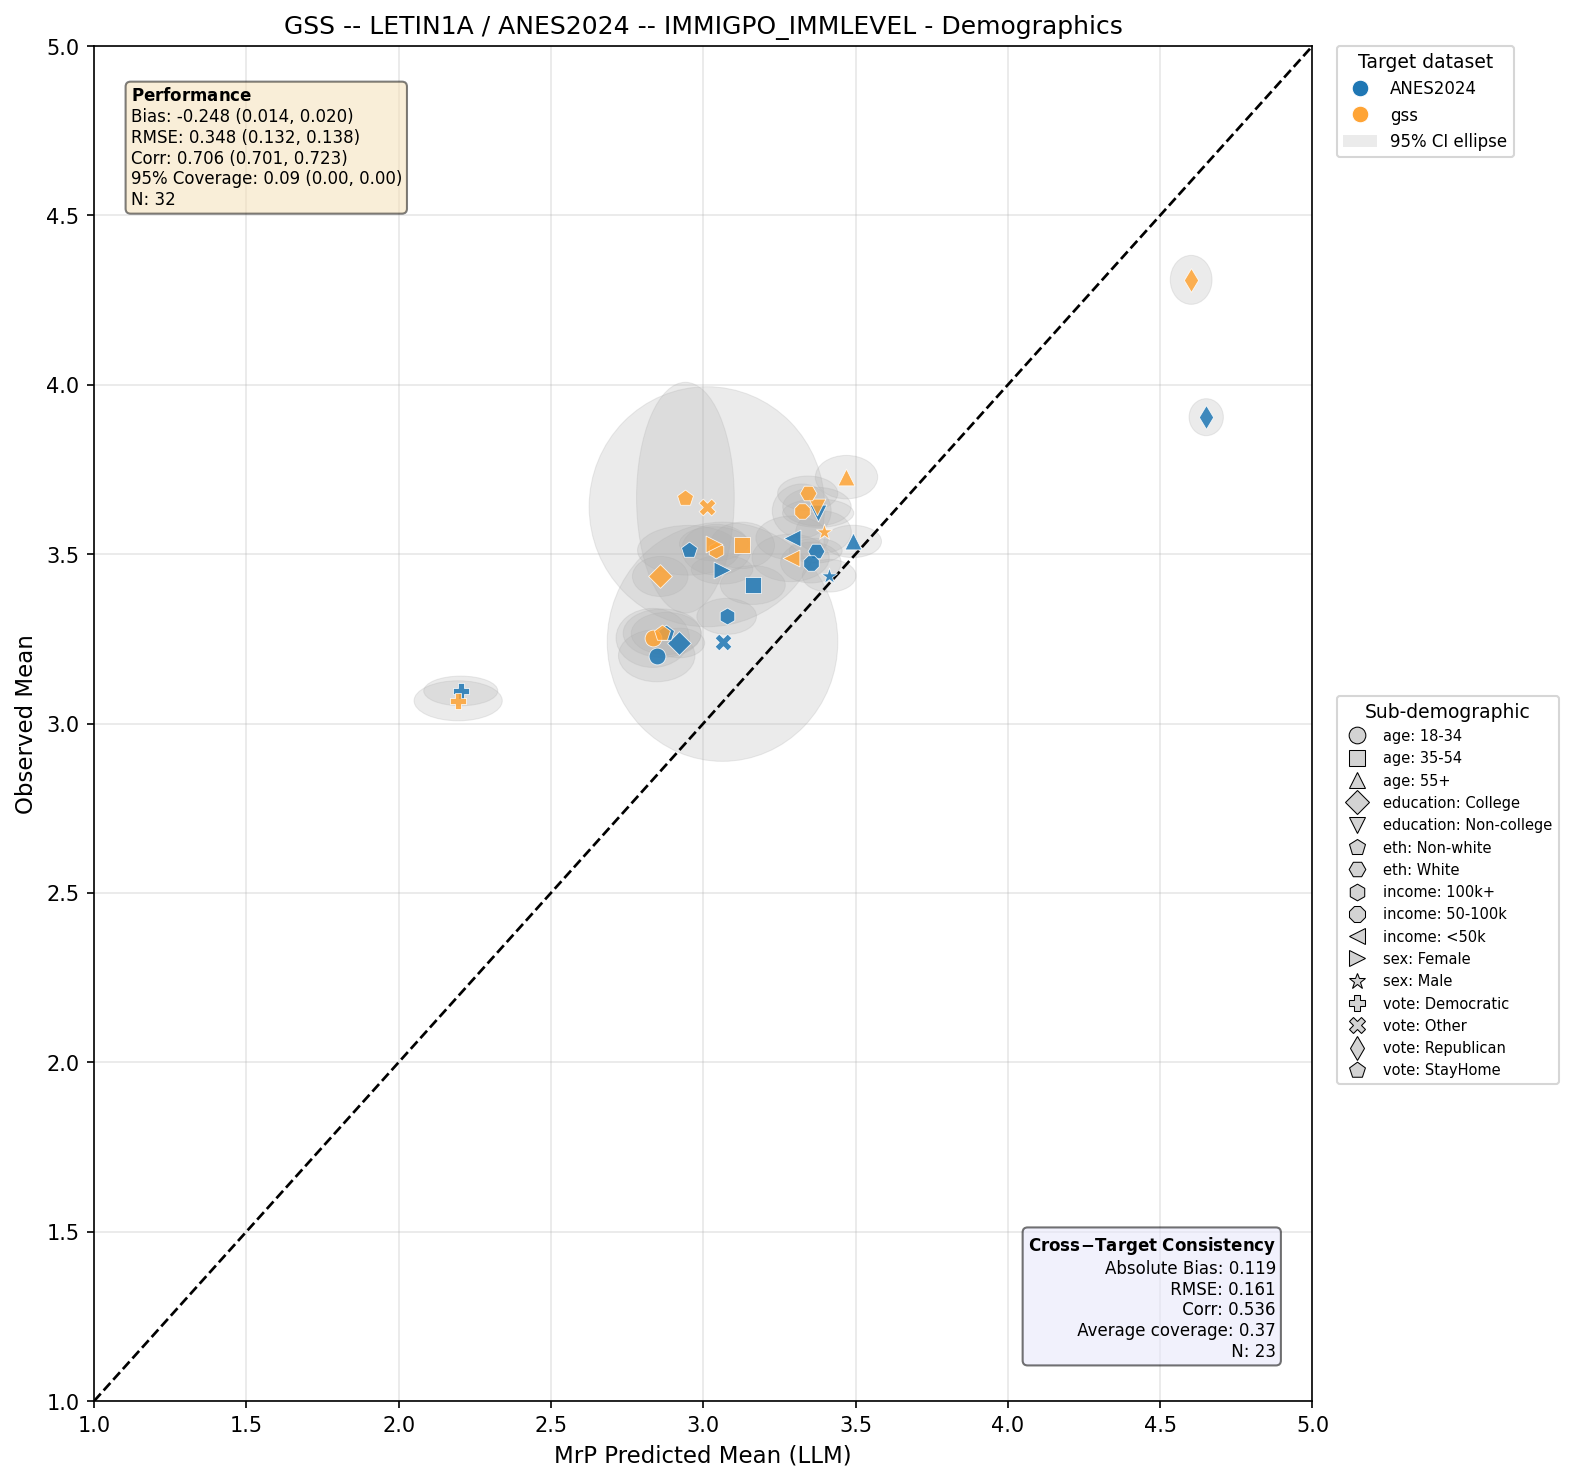

**State plot**

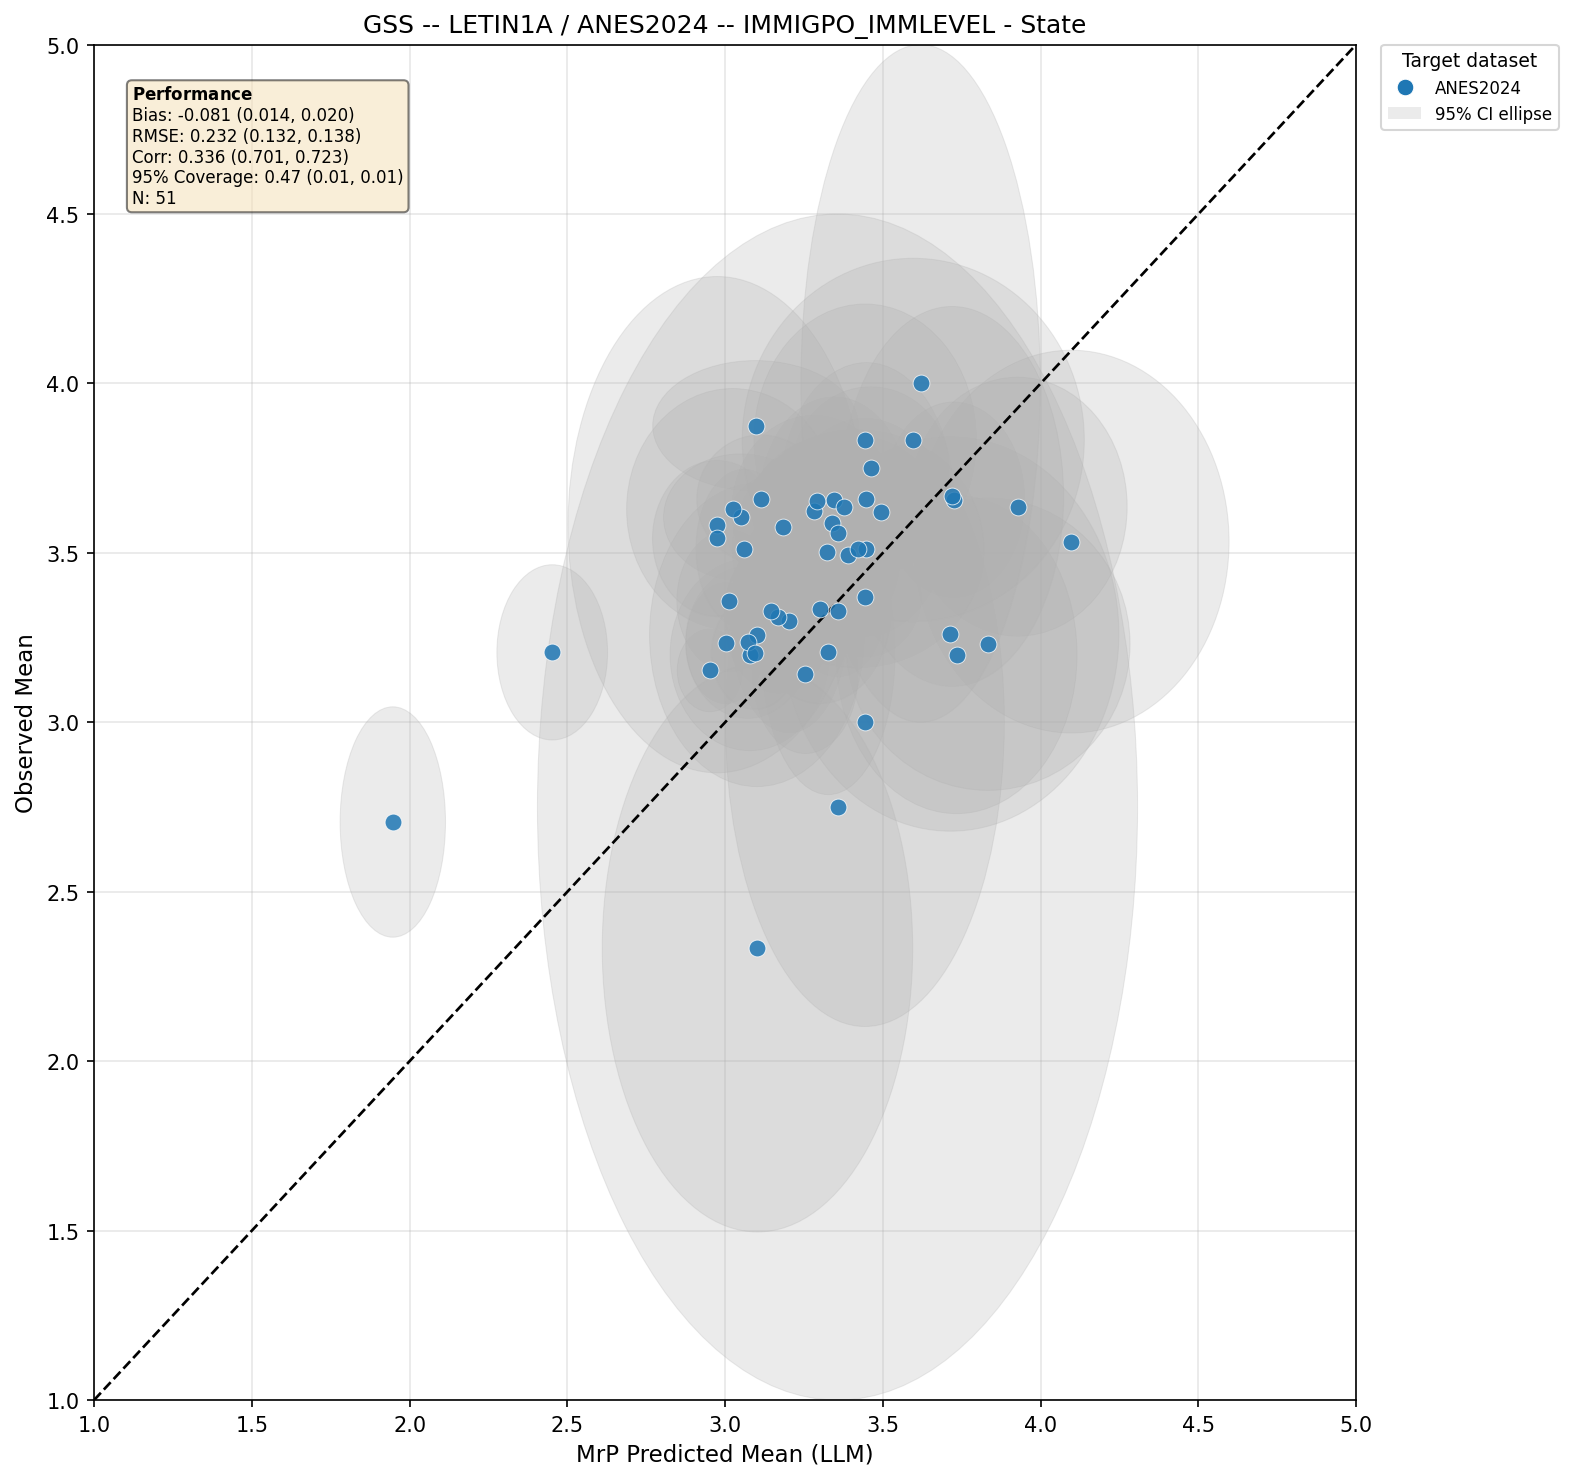

In [169]:
q_id = 'Belief_opinion_on_the_number_of_immigrants_in_america_Symbol'

safe_qid = q_id.removesuffix('_Symbol')
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data') / q_id / 'plot'


if not plot_dir.exists():
    print(f'Plot directory does not exist: {plot_dir}')
else:
    demo_path = plot_dir / f'{safe_qid}_demographics.png'
    state_path = plot_dir / f'{safe_qid}_state.png'

    shown_any = False

    if demo_path.exists():
        display(Markdown('**Demographics plot**'))
        display(Image(filename=str(demo_path)))
        shown_any = True

    if state_path.exists():
        display(Markdown('**State plot**'))
        display(Image(filename=str(state_path)))
        shown_any = True

    if not shown_any:
        print(f'No saved images found for q_id={q_id} in {plot_dir}')

**Demographics plot**

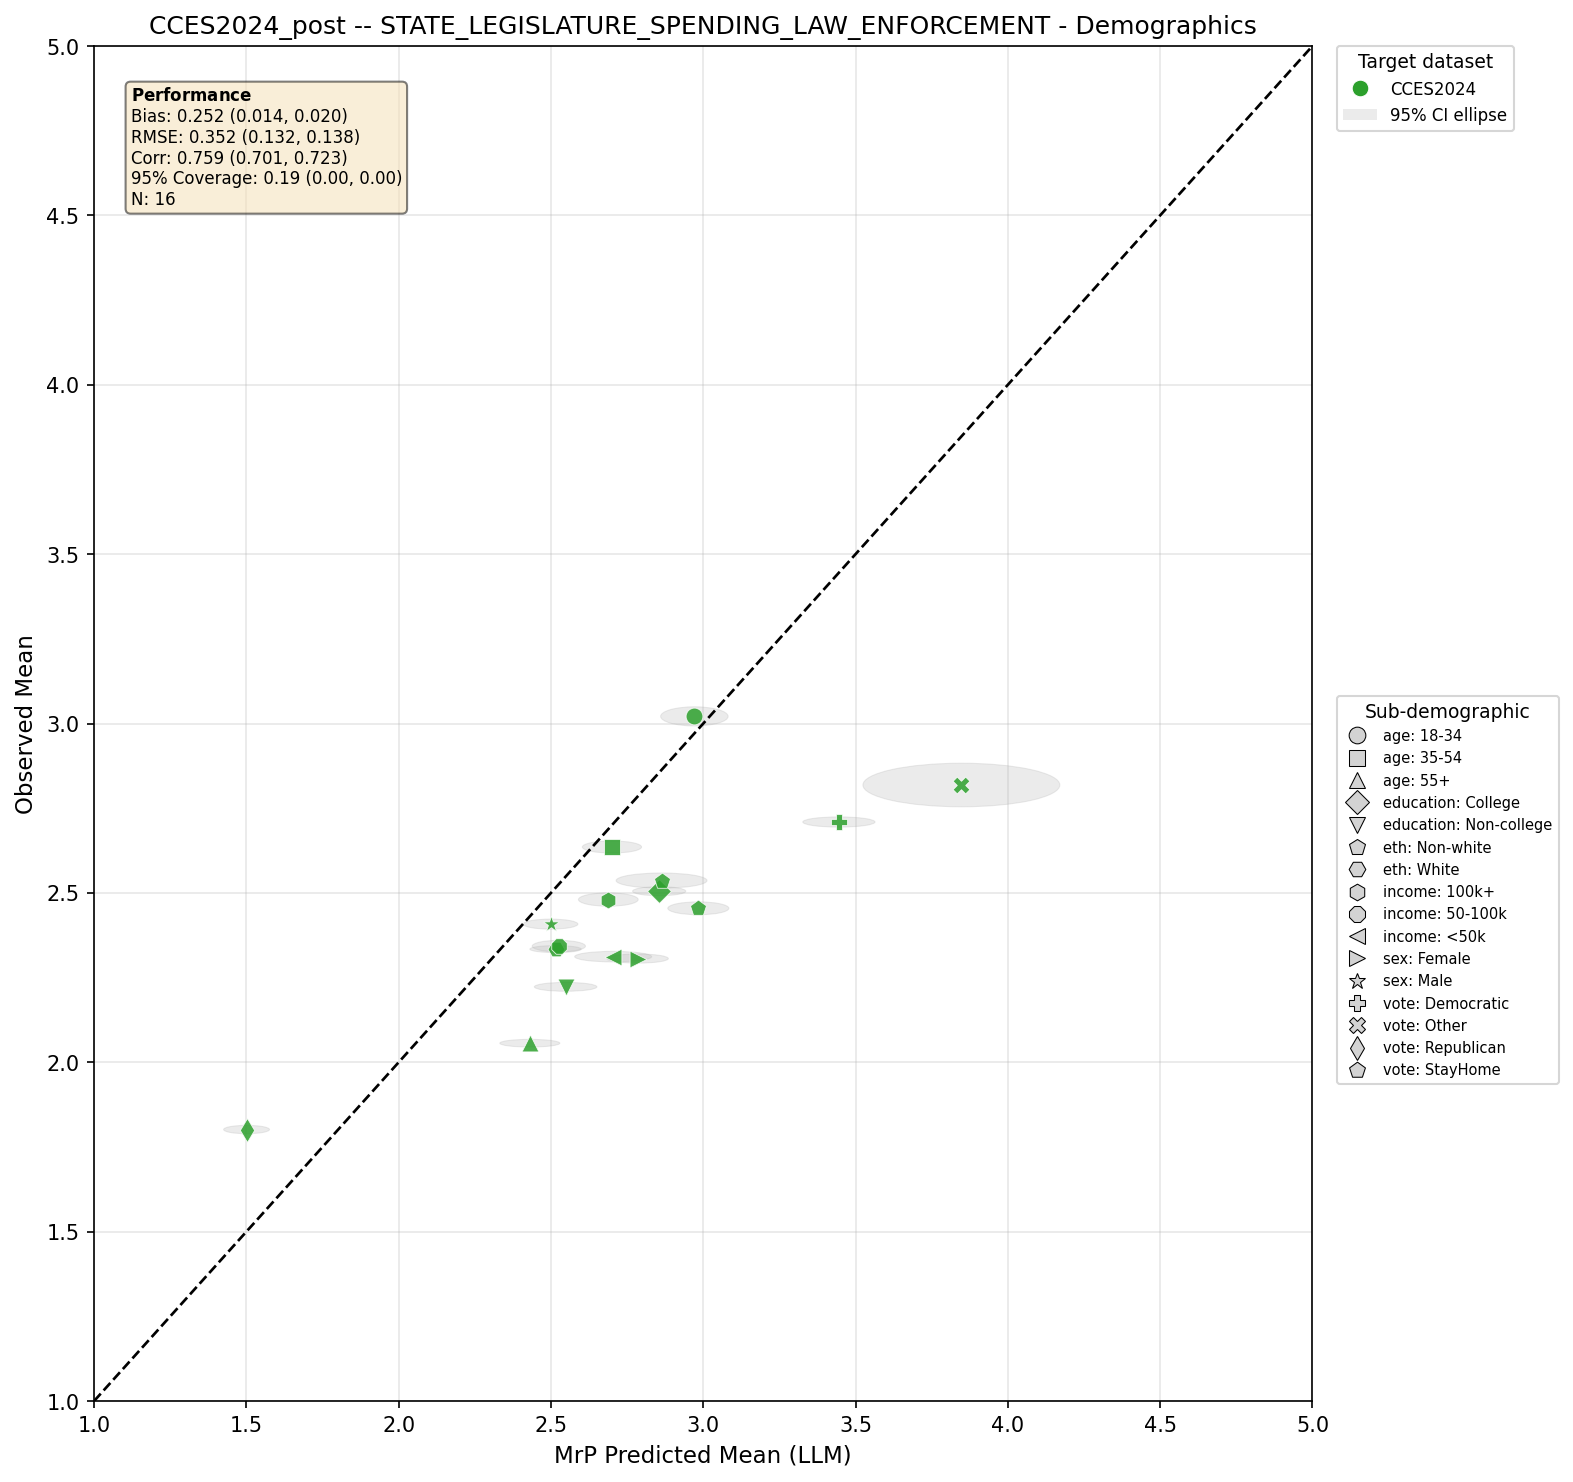

**State plot**

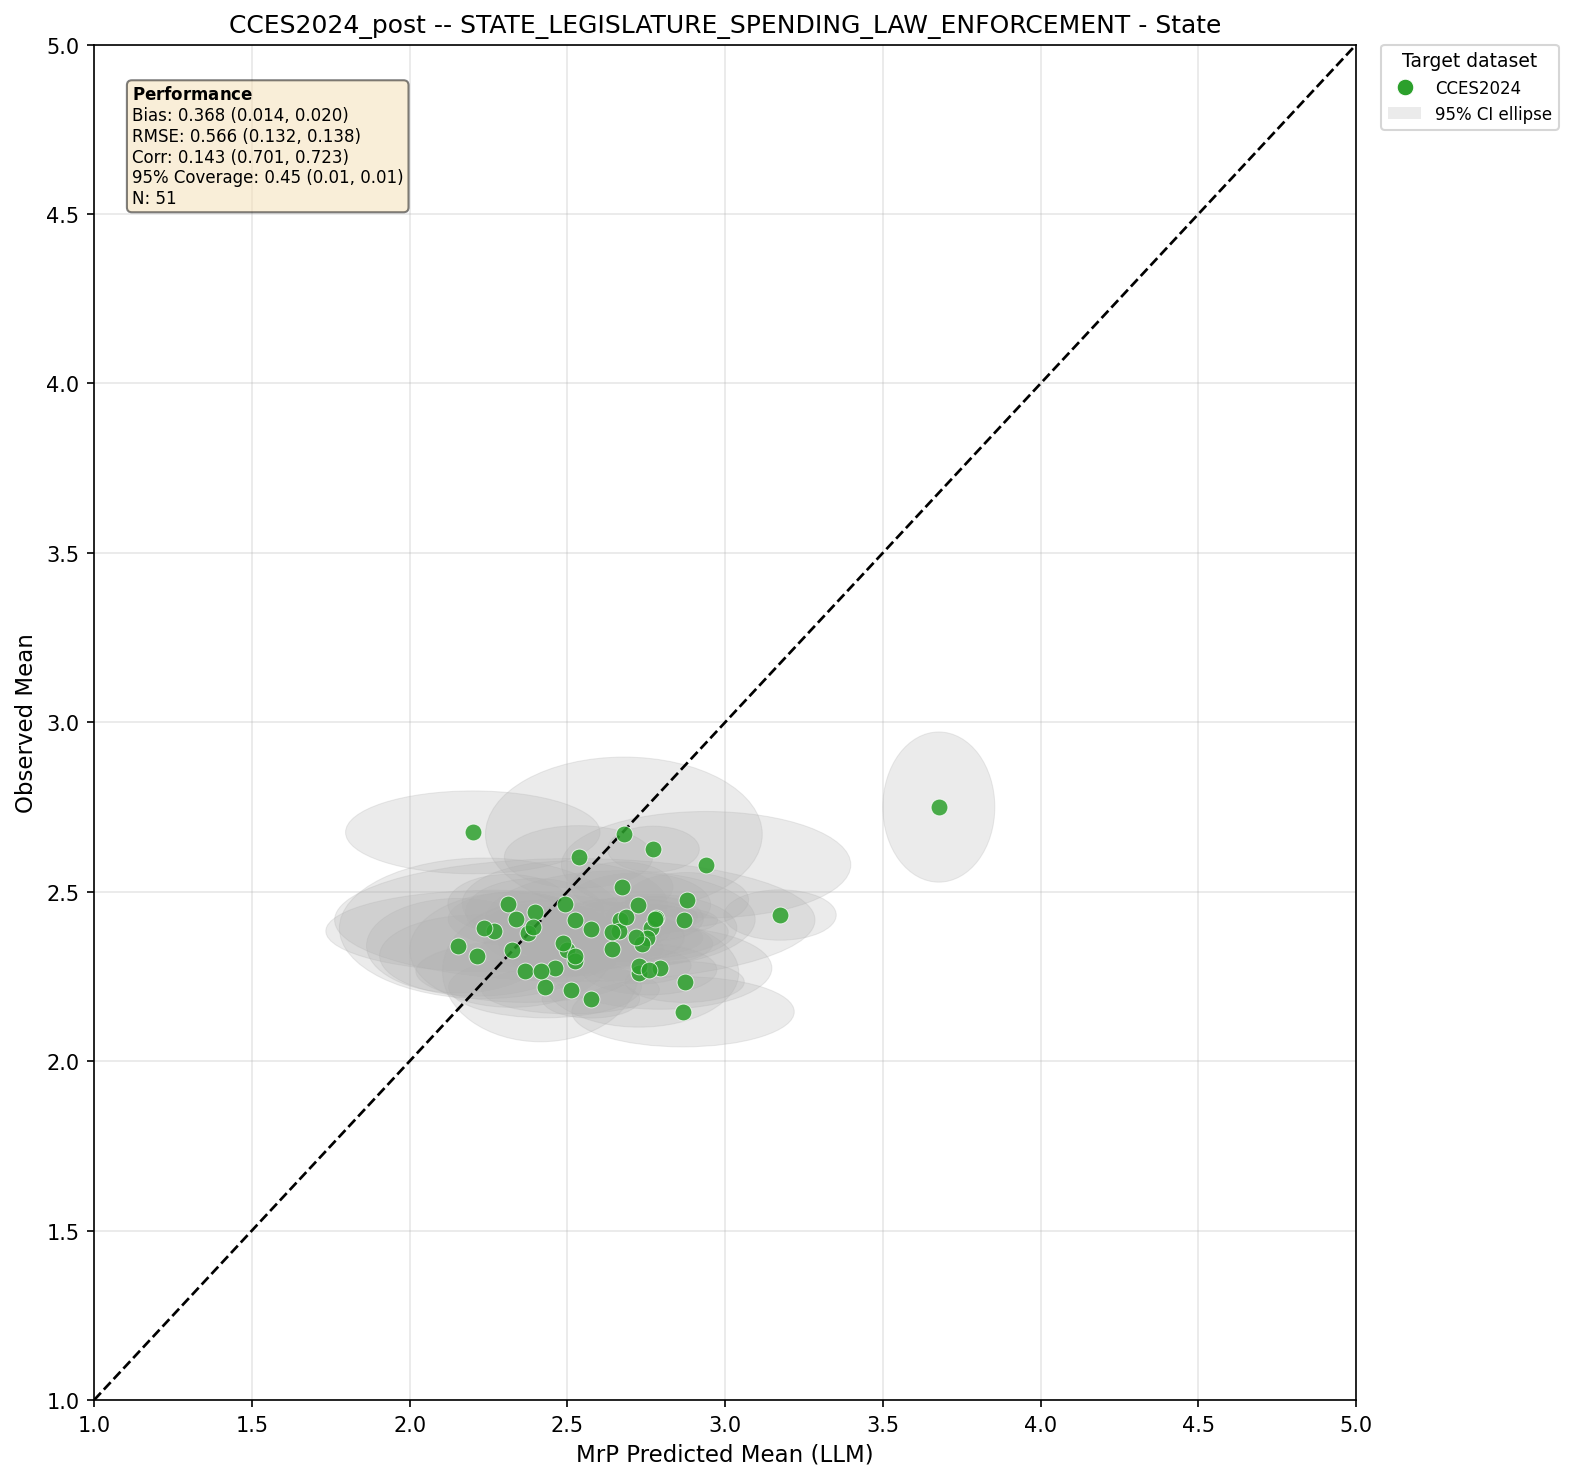

In [170]:


# Input question id
q_id = 'Belief_opinion_on_funding_of_police_departments_Symbol'

safe_qid = q_id.removesuffix('_Symbol')
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data') / q_id / 'plot'


if not plot_dir.exists():
    print(f'Plot directory does not exist: {plot_dir}')
else:
    demo_path = plot_dir / f'{safe_qid}_demographics.png'
    state_path = plot_dir / f'{safe_qid}_state.png'

    shown_any = False

    if demo_path.exists():
        display(Markdown('**Demographics plot**'))
        display(Image(filename=str(demo_path)))
        shown_any = True

    if state_path.exists():
        display(Markdown('**State plot**'))
        display(Image(filename=str(state_path)))
        shown_any = True

    if not shown_any:
        print(f'No saved images found for q_id={q_id} in {plot_dir}')

In [171]:
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,...,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,...,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,...,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,...,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,...,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,1.866142,1.823667,1.913354,1.812886,1.925402,...,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,...,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,...,2.775074,2.695410,2.764615,2.704859,2.756269,0.027199,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,...,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,2024-10-06 00:00:00+00:00,NaN,1,False


how to achivee this:
create a new dataframe called the standardized_plot_df, where all the observed and predicted means, quantiles and standard deviations are standardize to a 0-1 scale. give me the possible options for this standardization, as the value shown now is the expected y from an logistic regression. you can find the full question scale for each question_id from k = df[f"{question_id}_cat"].cat.categories.size, and the scale is 1-k

In [172]:
# Build standardized_plot_df on a 0-1 scale using each question's full category range (1..k).
from copy import deepcopy

def _infer_k_from_question_id(question_id, source_df):
    col = f"{question_id}_cat"
    if col not in source_df.columns:
        raise KeyError(f"Missing {col} in df; cannot infer k for {question_id}")
    return source_df[col].cat.categories.size

def _collect_scale_columns(input_df):
    # Means and interval bounds from both observed and predicted series.
    prefix_cols = [
        c for c in input_df.columns
        if c.startswith('obs_') or c.startswith('pred_')
    ]
    # Standard deviation-like columns (if present).
    std_cols = [
        c for c in input_df.columns
        if ('std' in c.lower() or c.lower().endswith('_sd'))
        and pd.api.types.is_numeric_dtype(input_df[c])
    ]
    scale_cols = sorted(set(prefix_cols + std_cols))
    return [c for c in scale_cols if pd.api.types.is_numeric_dtype(input_df[c])]

def standardize_plot_df(plot_df_input, source_df_for_k):
    """
    Standardize observed/predicted means, quantiles and std columns to 0-1.

    """
    out = deepcopy(plot_df_input)
    scale_cols = _collect_scale_columns(out)
    if not scale_cols:
        raise ValueError('No numeric obs_/pred_ or std-like columns found to scale.')

    k_map = {
        qid: _infer_k_from_question_id(qid, source_df_for_k)
        for qid in out['question_id'].dropna().unique()
    }
    denom = out['question_id'].map(lambda q: k_map[q] - 1).astype(float)
    if (denom <= 0).any():
        raise ValueError('Invalid denominator k-1 found. Check question category sizes.')

    for c in scale_cols:
        if 'std' in c.lower() or c.lower().endswith('_sd'):
            out[c] = out[c].astype(float) / denom
        else:
            out[c] = (out[c].astype(float) - 1.0) / denom


    # Clip numerical drift from floating point.
    for c in scale_cols:
        out[c] = out[c].clip(0.0, 1.0)

    return out

standardized_plot_df = standardize_plot_df(plot_df, df)

standardized_plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,0.466194,0.463422,0.469149,0.462524,0.470078,...,0.561236,0.510573,0.558084,0.515383,0.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,0.432068,0.429117,0.435072,0.427988,0.435894,...,0.407638,0.353896,0.401598,0.360228,0.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,0.622898,0.618569,0.627483,0.617586,0.628566,...,0.593602,0.529497,0.582162,0.534197,0.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,0.459884,0.456481,0.463203,0.455433,0.464800,...,0.502099,0.446310,0.494868,0.452625,0.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,0.378182,0.375076,0.381266,0.374639,0.382271,...,0.423178,0.370810,0.416490,0.377065,0.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,0.288714,0.274556,0.304451,0.270962,0.308467,...,0.593686,0.566090,0.590491,0.568519,0.587759,0.009374,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,0.292441,0.269285,0.309863,0.265604,0.314468,...,0.594740,0.569184,0.591809,0.570992,0.589165,0.009192,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,0.297568,0.283453,0.314269,0.278270,0.318964,...,0.591691,0.565137,0.588205,0.568286,0.585423,0.009066,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,0.309353,0.290878,0.323987,0.287091,0.329735,...,0.593649,0.566205,0.590751,0.568052,0.588217,0.009771,2024-10-06 00:00:00+00:00,NaN,1,False


In [173]:
plot_df['grouping_var'].unique()

array(['sex', 'age', 'income', 'eth', 'education', 'vote', 'state',
       'time_window_bin'], dtype=object)

In [174]:
# Debug national merge path: check if time_window_bin exists in each stage.
print('agg_target_df grouping_var:', agg_target_df['grouping_var'].value_counts())
print('llm_df grouping_var:', llm_df['grouping_var'].value_counts())
print('plot_df grouping_var:', plot_df['grouping_var'].value_counts())
print('standardized_plot_df grouping_var:', standardized_plot_df['grouping_var'].value_counts())

print('sample agg_target_df time_window_bin:', agg_target_df[agg_target_df['grouping_var'] == 'time_window_bin'].head(3))
print('sample llm_df time_window_bin:', llm_df[llm_df['grouping_var'] == 'time_window_bin'].head(3))

agg_target_df grouping_var: grouping_var
state              1120
time_window_bin     444
vote                156
age                 117
income              117
sex                  78
eth                  78
education            78
Name: count, dtype: int64
llm_df grouping_var: grouping_var
state              1989
time_window_bin     509
vote                156
age                 117
income              117
sex                  78
eth                  78
education            78
Name: count, dtype: int64
plot_df grouping_var: grouping_var
state              1120
time_window_bin     405
vote                156
age                 117
income              117
sex                  78
eth                  78
education            78
Name: count, dtype: int64
standardized_plot_df grouping_var: grouping_var
state              1120
time_window_bin     405
vote                156
age                 117
income              117
sex                  78
eth                  78
education           

using data from the standardized_plot_df, i want to plot across all beleifs:
a) a demographic plot that includes all the dots from the per-question demo plot(pairs between prediction and targets from different benchmakr dataset) across beleifs on one plot, also compute the ceilling metrics and the performance metrics using all pairs across beleifs
b) a state plot that includes all the dots from the per-question state plot, and compute the performance metrics using all pairs across beleifs(no ceilling metrics here)

In [175]:
test = target_boot_df[(target_boot_df["draw_idx"] == 0) & (target_boot_df["category"] == "Female")]
len(test)

39

In [176]:
llm_draws_df

,category,draw_1,draw_2,draw_3,draw_4,draw_5,draw_6,draw_7,draw_8,draw_9,...,draw_244,draw_245,draw_246,draw_247,draw_248,draw_249,draw_250,grouping_var,question_id,benchmark
0,Female,1.560497,1.559352,1.548582,1.560034,1.494525,1.518551,1.532482,1.546119,1.556579,...,1.526319,1.515289,1.520987,1.584025,1.546293,1.549319,1.509409,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
1,Male,1.402220,1.408153,1.411364,1.386999,1.374658,1.381027,1.360168,1.378403,1.370564,...,1.386519,1.373770,1.364862,1.385974,1.398391,1.387599,1.402713,sex,Belief_increase_fossil_fuel_production_Symbol,CCES2024
2,18-34,1.577508,1.623263,1.573244,1.562884,1.539791,1.532088,1.537310,1.569039,1.551623,...,1.556636,1.549085,1.547240,1.566784,1.580501,1.584020,1.573450,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
3,35-54,1.490205,1.506828,1.501740,1.502392,1.457371,1.470252,1.451222,1.481187,1.476607,...,1.466453,1.446968,1.477153,1.511586,1.477572,1.490189,1.471254,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
4,55+,1.427265,1.398727,1.419059,1.410979,1.366041,1.395841,1.396708,1.399010,1.410074,...,1.399879,1.389994,1.369713,1.430773,1.412730,1.396594,1.384634,age,Belief_increase_fossil_fuel_production_Symbol,CCES2024
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3117,"[2024-10-06 , 2024-10-20)",2.750914,2.714799,2.735129,2.725133,2.725751,2.747654,2.723160,2.753819,2.739373,...,2.746280,2.762815,2.747662,2.730881,2.765742,2.703541,2.745411,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3118,"[2024-08-25 , 2024-09-08)",2.726914,2.706969,2.735113,2.719350,2.721132,2.761070,2.705496,2.747286,2.747341,...,2.766863,2.736478,2.754774,2.712296,2.759784,2.690242,2.745702,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3119,"[2024-09-08 , 2024-09-22)",2.746327,2.715957,2.734144,2.721881,2.738506,2.758418,2.751488,2.725061,2.773514,...,2.764547,2.709086,2.750694,2.716338,2.766625,2.698353,2.759927,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024
3120,"[2024-10-20 , 2024-11-03)",2.736853,2.757351,2.735510,2.722295,2.727612,2.743186,2.733691,2.744971,2.742610,...,2.735936,2.740237,2.738126,2.716759,2.743829,2.723391,2.761631,time_window_bin,Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024


In [177]:
def standardize_draw_level_inputs(llm_draws_df_input, target_boot_df_input, source_df_for_k, n_draws=250):
    """
    Standardize draw-level inputs to 0-1 using per-question scale 1..k.
    - posterior draw columns in llm_draws_df: (x - 1) / (k - 1)
    - target bootstrap means in target_boot_df['obs_boot_mean']: (x - 1) / (k - 1)
    """
    key_cols = ['grouping_var', 'category', 'question_id', 'benchmark']

    llm_draws_std = llm_draws_df_input.copy()
    target_boot_std = target_boot_df_input.copy()

    qids = pd.Index(
        llm_draws_std['question_id'].dropna().astype(str).unique()
    ).union(
        target_boot_std['question_id'].dropna().astype(str).unique()
    )

    k_map = {qid: _infer_k_from_question_id(qid, source_df_for_k) for qid in qids}

    if llm_draws_std.empty:
        raise ValueError('llm_draws_df is empty.')
    if target_boot_std.empty:
        raise ValueError('target_boot_df is empty.')

    denom_pred = llm_draws_std['question_id'].astype(str).map(lambda q: float(k_map[q] - 1))
    denom_targ = target_boot_std['question_id'].astype(str).map(lambda q: float(k_map[q] - 1))

    if (denom_pred <= 0).any() or (denom_targ <= 0).any():
        raise ValueError('Invalid denominator k-1 while standardizing draw-level inputs.')

    meta_cols = set(key_cols + ['draw_idx'])
    non_draw_numeric = {
        'pred_mean', 'pred_lower_68', 'pred_upper_68',
        'pred_lower_80', 'pred_upper_80',
        'pred_lower_90', 'pred_upper_90',
        'pred_lower_95', 'pred_upper_95', 'n'
    }
    draw_cols = [
        c for c in llm_draws_std.columns
        if c not in meta_cols
        and c not in non_draw_numeric
        and pd.api.types.is_numeric_dtype(llm_draws_std[c])
    ]
    if not draw_cols:
        raise ValueError('No numeric posterior draw columns found in llm_draws_df.')

    draw_cols = draw_cols[:n_draws]

    # Standardize posterior draws and interval summaries if present.
    for c in draw_cols:
        llm_draws_std[c] = (llm_draws_std[c].astype(float) - 1.0) / denom_pred

    for c in [
        'pred_mean', 'pred_lower_68', 'pred_upper_68',
        'pred_lower_80', 'pred_upper_80',
        'pred_lower_90', 'pred_upper_90',
        'pred_lower_95', 'pred_upper_95'
    ]:
        if c in llm_draws_std.columns:
            llm_draws_std[c] = (llm_draws_std[c].astype(float) - 1.0) / denom_pred

    # Standardize target bootstrap means.
    if 'obs_boot_mean' not in target_boot_std.columns:
        raise ValueError('target_boot_df must contain obs_boot_mean.')
    target_boot_std['obs_boot_mean'] = (target_boot_std['obs_boot_mean'].astype(float) - 1.0) / denom_targ

    # Clip numerical drift.
    for c in draw_cols:
        llm_draws_std[c] = llm_draws_std[c].clip(0.0, 1.0)
    for c in ['pred_mean', 'pred_lower_95', 'pred_upper_95']:
        if c in llm_draws_std.columns:
            llm_draws_std[c] = llm_draws_std[c].clip(0.0, 1.0)
    target_boot_std['obs_boot_mean'] = target_boot_std['obs_boot_mean'].clip(0.0, 1.0)

    return llm_draws_std, target_boot_std

In [ ]:
# Standardize draw-level inputs so compute_metrics uses the same 0-1 scale as standardized_plot_df.
llm_draws_std, target_boot_std = standardize_draw_level_inputs(
    llm_draws_df, target_boot_df, df, n_draws=250
)

demo_all = standardized_plot_df[~standardized_plot_df['grouping_var'].isin(['state', 'time_window_bin'])].copy()
state_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'state'].copy()

if demo_all.empty:
    raise ValueError('No demographic rows found in standardized_plot_df.')
if state_all.empty:
    raise ValueError('No state rows found in standardized_plot_df.')

# Reuse the original compute_metrics logic (draw-matched posterior vs bootstrap).
demo_perf = compute_metrics(
    demo_all,
    llm_draws_df=llm_draws_std,
    target_boot_df=target_boot_std
)
state_perf = compute_metrics(
    state_all,
    llm_draws_df=llm_draws_std,
    target_boot_df=target_boot_std
)

# Demographic pooled ceiling metrics (no ceiling for state).
demo_ceiling_pairwise = compute_obs_pairwise(demo_all)
demo_ceiling = compute_obs_pairwise_metrics(demo_ceiling_pairwise, ci_level=95)

# Save paths.
out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
out_dir.mkdir(parents=True, exist_ok=True)
demo_out = out_dir / 'all_beliefs_demographics.png'
state_out = out_dir / 'all_beliefs_state.png'

# Plot + save demographics using the same per-question plotting function.
fig_demo, ax_demo = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_demo,
    demo_all,
    metrics=demo_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=demo_ceiling,
    state=False,
    standardized_axis=True
)
fig_demo.tight_layout(rect=[0, 0, 0.78, 1])
fig_demo.savefig(demo_out, dpi=200, bbox_inches='tight')
plt.close(fig_demo)

# Plot + save state using the same per-question plotting function.
fig_state, ax_state = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_state,
    state_all,
    metrics=state_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=None,
    state=True,
    standardized_axis=True
)
fig_state.tight_layout(rect=[0, 0, 0.78, 1])
fig_state.savefig(state_out, dpi=200, bbox_inches='tight')
plt.close(fig_state)

print('Saved:', demo_out)
print('Saved:', state_out)
print('Demographic pooled performance:', demo_perf)
print('Demographic pooled ceiling:', demo_ceiling)
print('State pooled performance:', state_perf)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots/all_beliefs_demographics.png
Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots/all_beliefs_state.png
Demographic pooled performance: {'bias_mean': 0.02042006374802353, 'bias_ci': (0.024297184248314382, 0.03364552697093817), 'rmse_mean': 0.18482067520519727, 'rmse_ci': (0.1932107622920667, 0.20157194037416662), 'corr_mean': 0.5495507129677919, 'corr_ci': (0.48096559738414796, 0.5129204195531675), 'coverage_mean': 0.15705128205128205, 'coverage_ci': (0.04157373072238931, 0.04805841846240101), 'n': 624, 'n_cells': 2149}
Demographic pooled ceiling: {'bias_mean': np.float64(0.07434052826832208), 'rmse_mean': np.float64(0.16049299078718904), 'corr_mean': np.float64(0.8076487071294944), 'cov_sym_mean': np.float64(0.2784090909090909), 'n': 176}
State pooled performance: {'bias_mean': 0.037351420992410664, 'bias_ci': (0.024297184248314382, 0.03364552697093817), '

# in the next cell compute the correlation

In [180]:
# National-level plot across all beliefs (time windows).

national_all = standardized_plot_df[standardized_plot_df['grouping_var'] == 'time_window_bin'].copy()
if national_all.empty:
    raise ValueError('No national time_window_bin rows found in standardized_plot_df.')

national_perf = compute_metrics(
    national_all,
    llm_draws_df=llm_draws_std,
    target_boot_df=target_boot_std
 )
national_ceiling_pairwise = compute_obs_pairwise(national_all)
national_ceiling = compute_obs_pairwise_metrics(national_ceiling_pairwise, ci_level=95)

out_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
out_dir.mkdir(parents=True, exist_ok=True)
national_out = out_dir / 'national_time_window_scatter.png'

fig_nat, ax_nat = plt.subplots(1, 1, figsize=(14, 10))
plot_scatter_with_uncertainty_ellipses(
    ax_nat,
    national_all,
    metrics=national_perf,
    ci_level=95,
    question_id=None,
    benchmark=None,
    ceiling_metrics=national_ceiling,
    state=None,
    standardized_axis=True
 )
fig_nat.tight_layout(rect=[0, 0, 0.78, 1])
fig_nat.savefig(national_out, dpi=200, bbox_inches='tight')
plt.close(fig_nat)

print('Saved:', national_out)
print('National pooled performance:', national_perf)
print('National pooled ceiling:', national_ceiling)

Saved: /mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots/national_time_window_scatter.png
National pooled performance: {'bias_mean': 0.017491388231583253, 'bias_ci': (0.024297184248314382, 0.03364552697093817), 'rmse_mean': 0.18899643157430873, 'rmse_ci': (0.1932107622920667, 0.20157194037416662), 'corr_mean': 0.4660808325694572, 'corr_ci': (0.48096559738414796, 0.5129204195531675), 'coverage_mean': 0.11604938271604938, 'coverage_ci': (0.015058411214953271, 0.024251187245590233), 'n': 405, 'n_cells': 2149}
National pooled ceiling: {'bias_mean': np.float64(0.09638659905517206), 'rmse_mean': np.float64(0.19048634707137818), 'corr_mean': np.float64(0.7193940515858326), 'cov_sym_mean': np.float64(0.3698630136986301), 'n': 73}


**National time window plot**

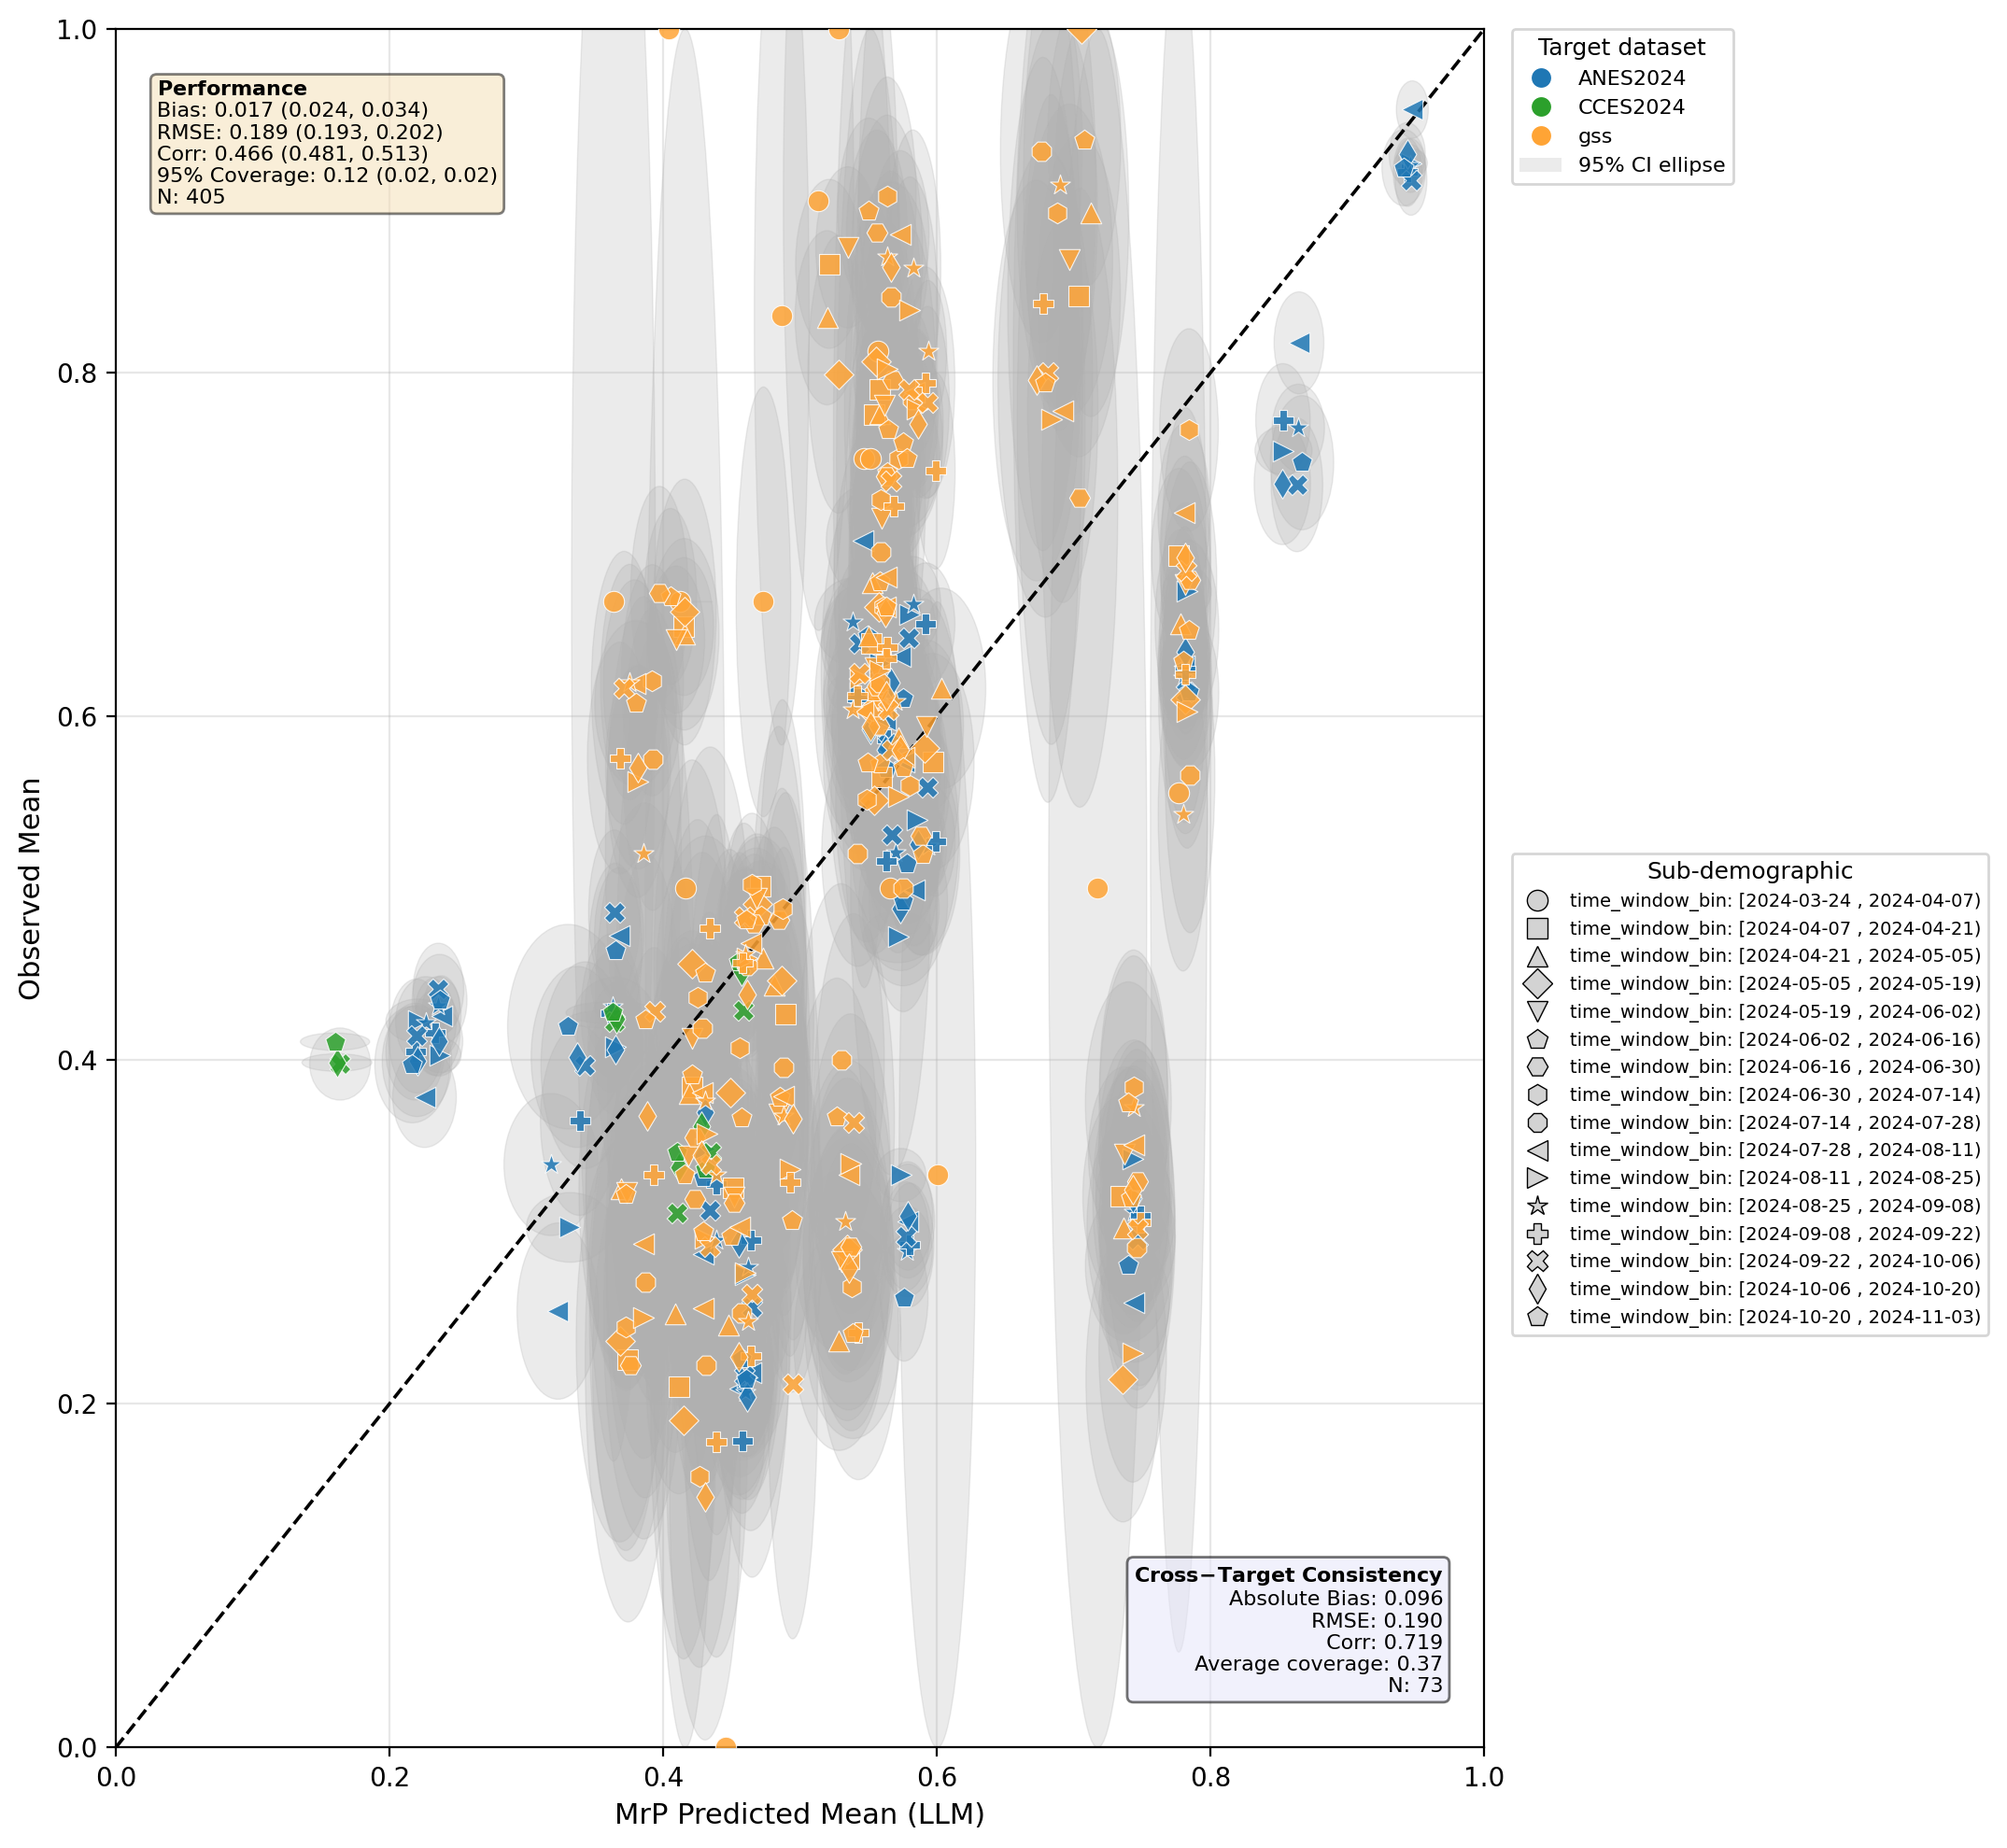

In [181]:
plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/national_plots')
national_path = plot_dir / 'national_time_window_scatter.png'

if not plot_dir.exists():
    print(f'Plot directory does not exist: {plot_dir}')
elif national_path.exists():
    display(Markdown('**National time window plot**'))
    display(Image(filename=str(national_path)))
else:
    print(f'Missing file: {national_path}')

**All beliefs: demographics plot**

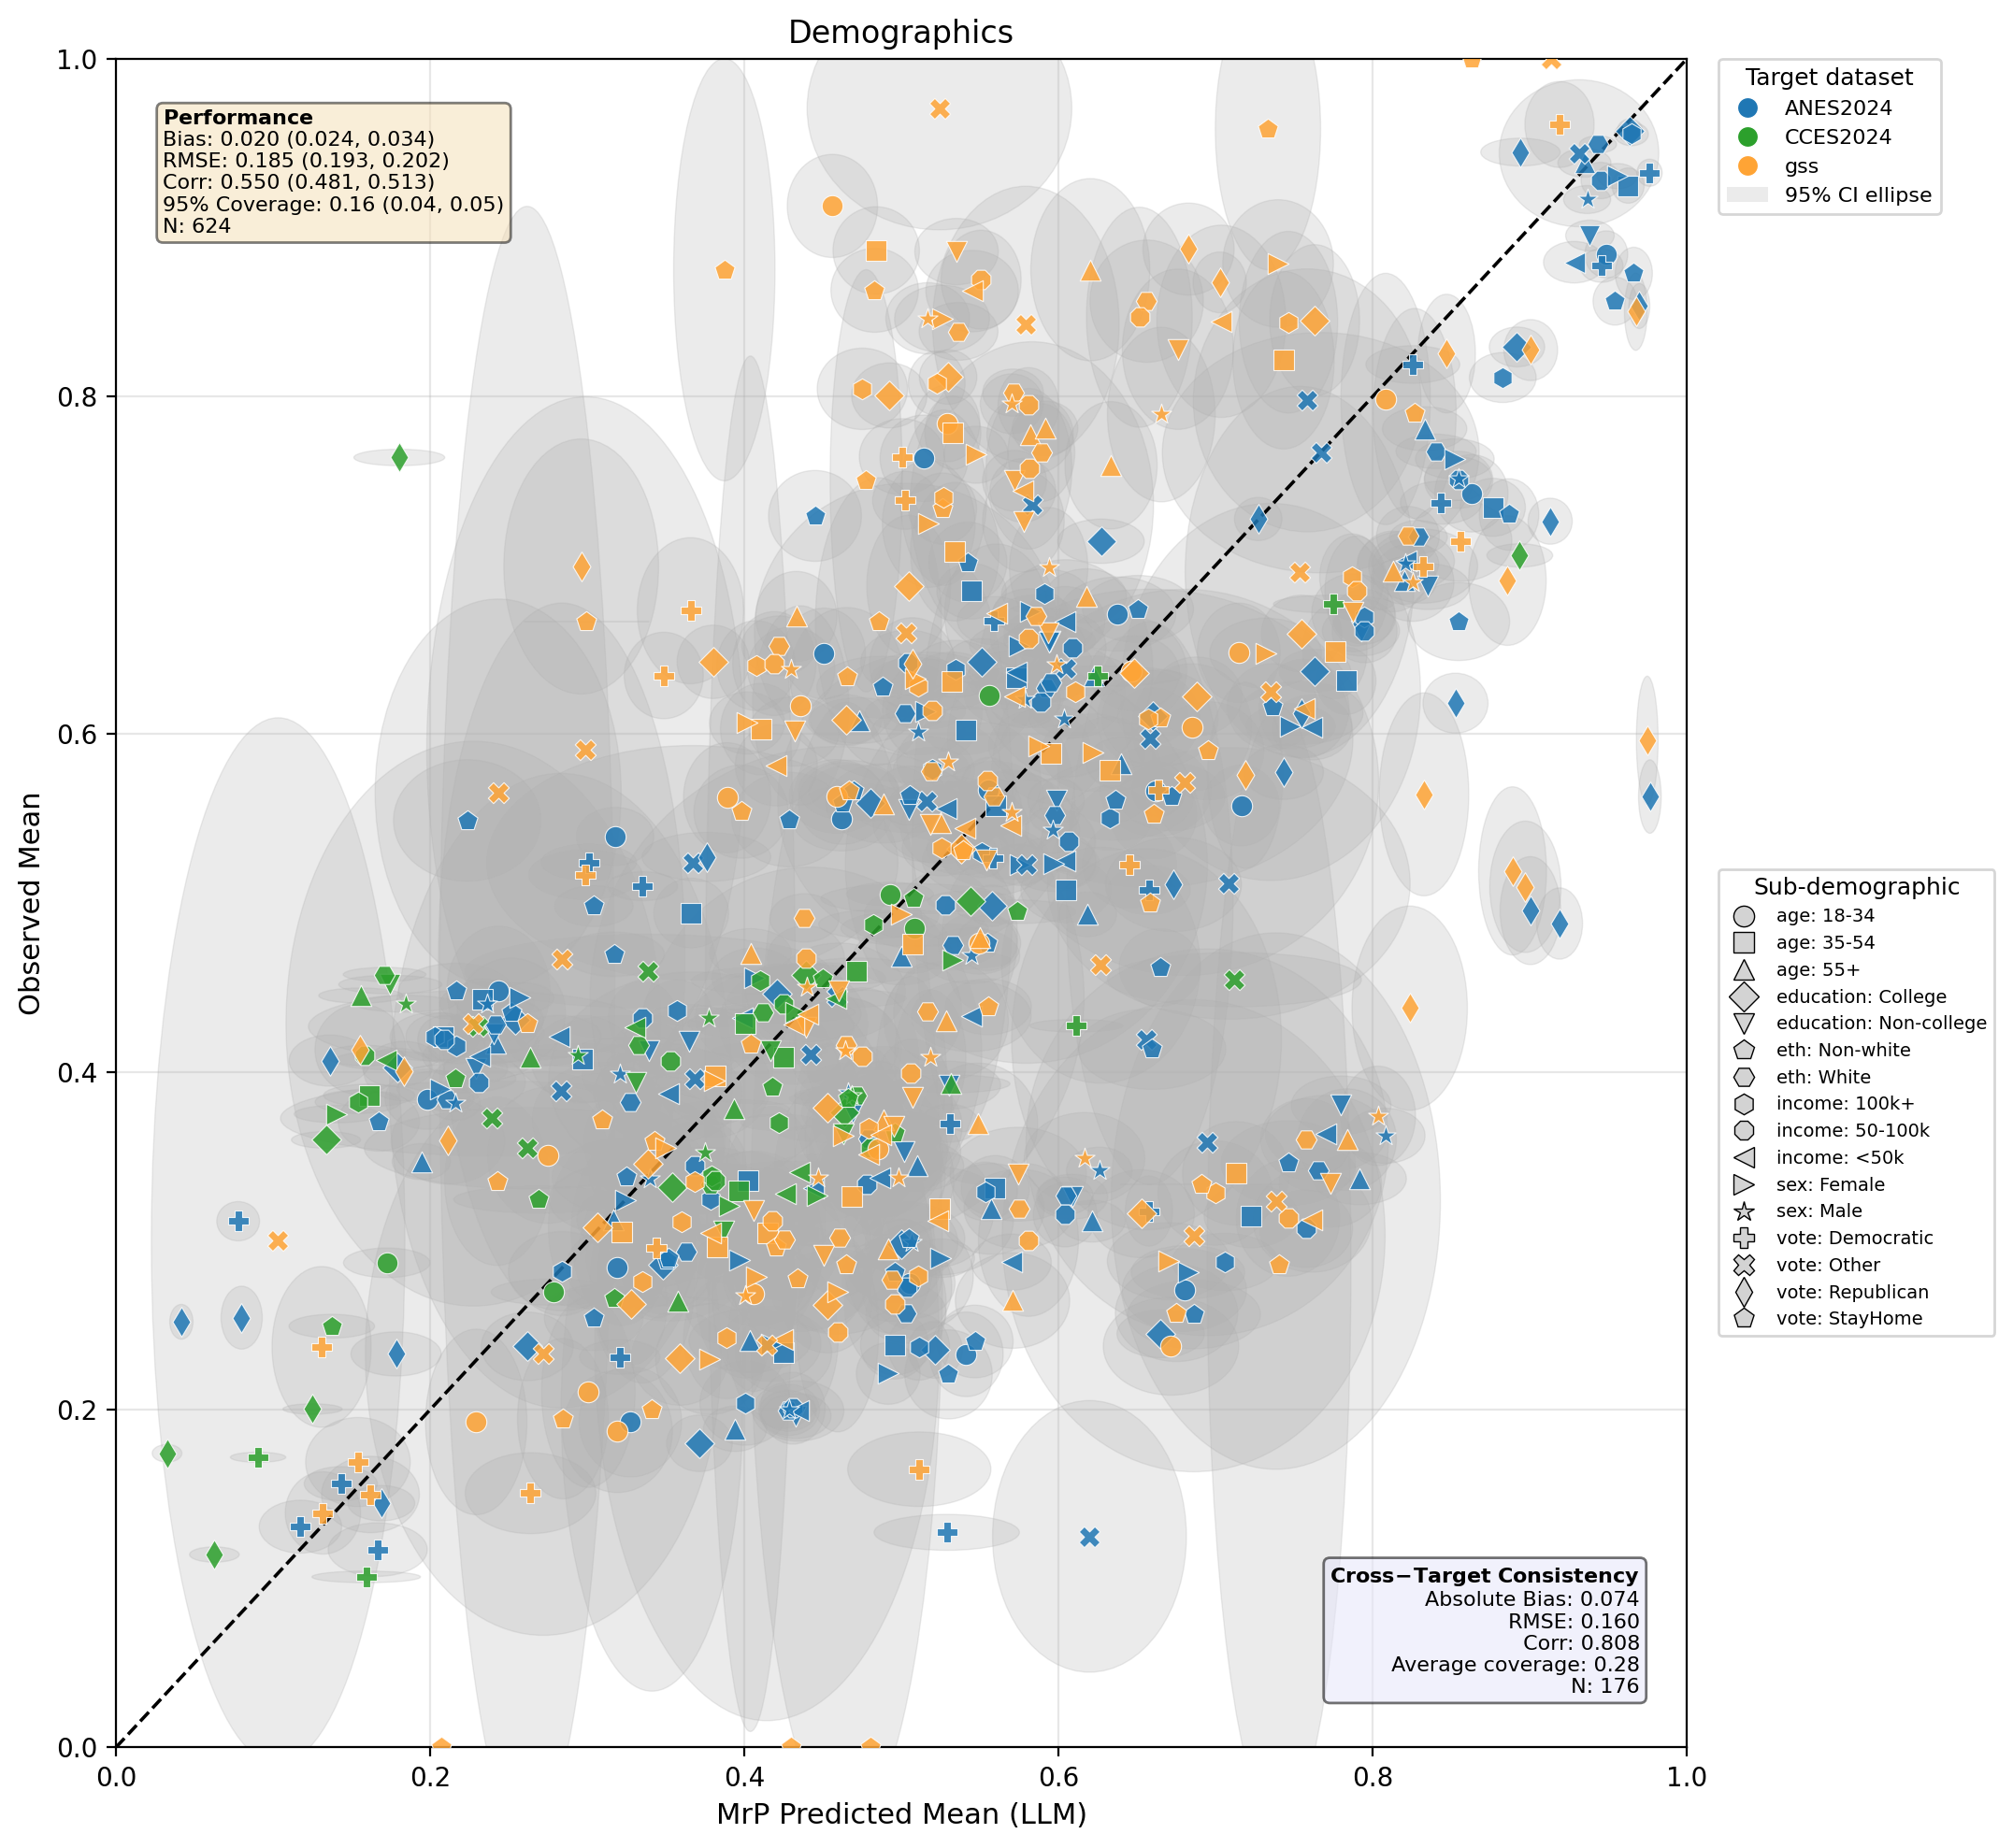

**All beliefs: state plot**

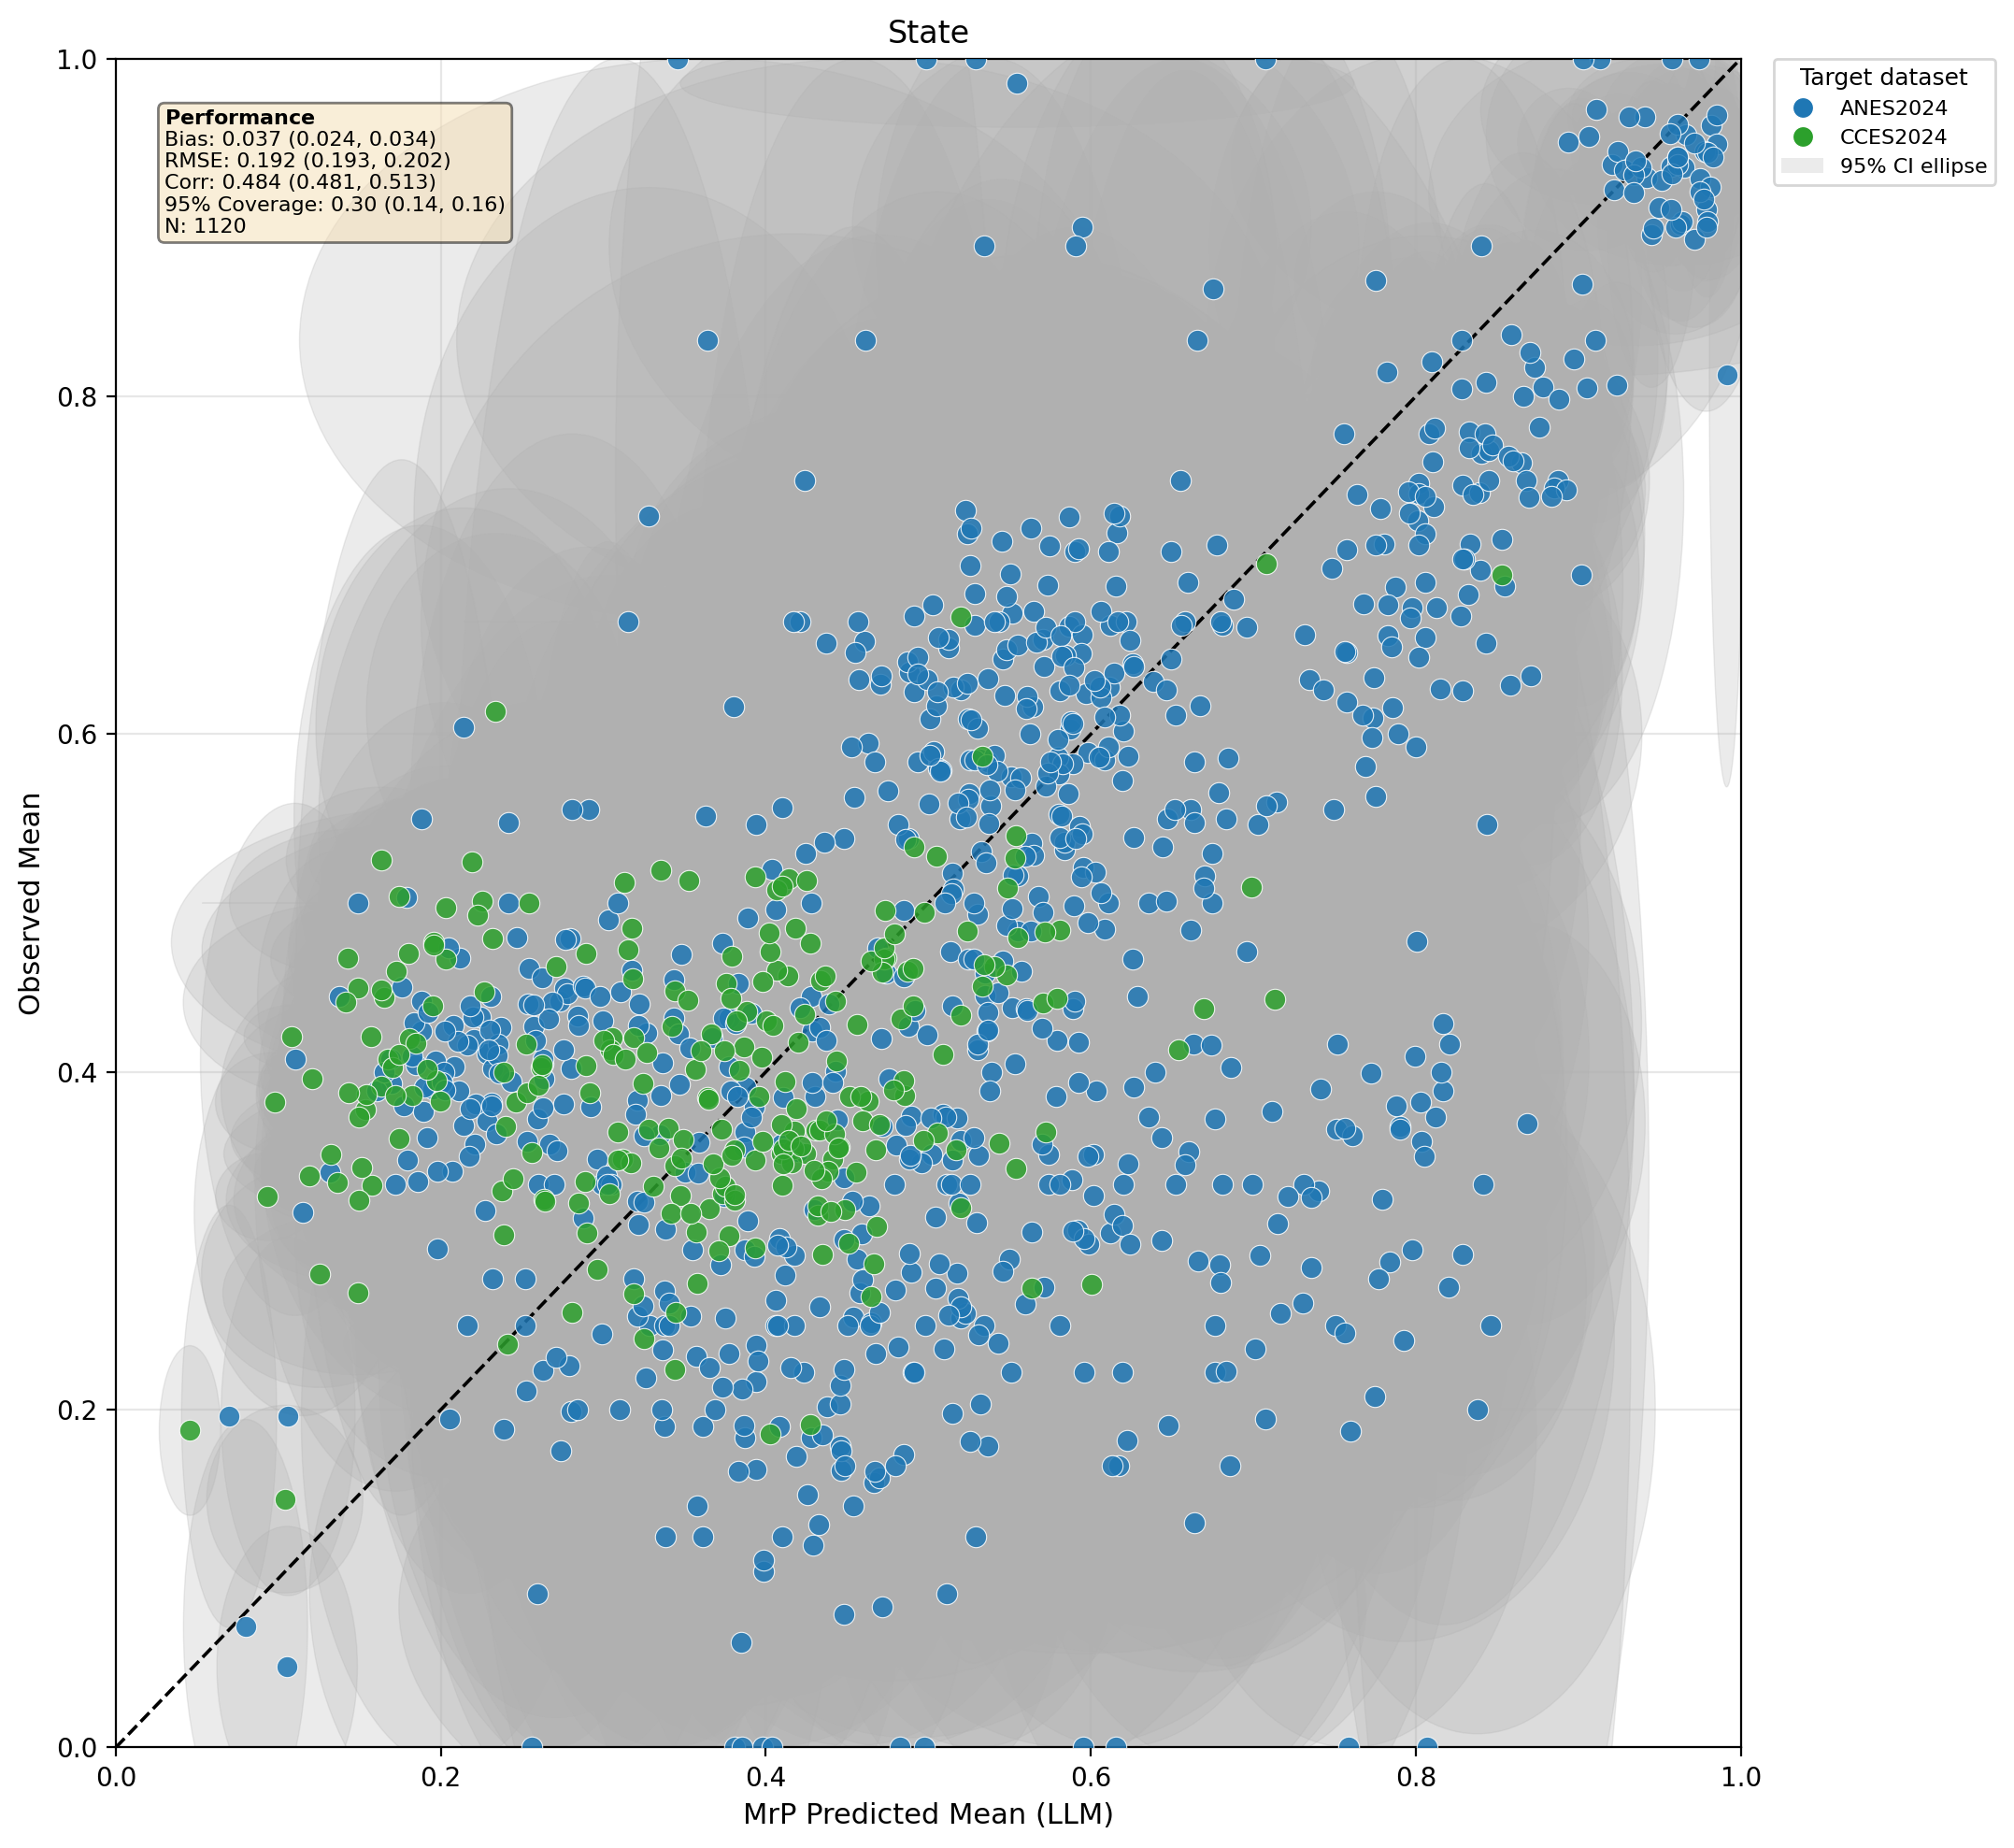

In [182]:


plot_dir = Path('/mnt/e/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/all_belief_plots')
demo_path = plot_dir / 'all_beliefs_demographics.png'
state_path = plot_dir / 'all_beliefs_state.png'

if not plot_dir.exists():
    print(f'Plot directory does not exist: {plot_dir}')
else:
    shown_any = False

    if demo_path.exists():
        display(Markdown('**All beliefs: demographics plot**'))
        display(Image(filename=str(demo_path)))
        shown_any = True
    else:
        print(f'Missing file: {demo_path}')

    if state_path.exists():
        display(Markdown('**All beliefs: state plot**'))
        display(Image(filename=str(state_path)))
        shown_any = True
    else:
        print(f'Missing file: {state_path}')

    if not shown_any:
        print('No saved plot images were found.')

without changing the code explain a step by step plan on how can i write a function for national level result. We want to do a scatter plot similar to what we are plotting now, each data point would be a time window x belief x target dataset combination. X-axis would be MrP predicted mean and Y-axis would be observed mean. Different colors of the dots stands for different target datasets. Ellispe are the uncertainty level So instead of using only one time window per target like what is been down right now, we want to use different time windows as different datapoint.  list what additional information is needed to make these plot. For the target, right now in df_obs there is a column for "time_window_bin", so the national level result can just be computed the same way as any other group_vars, and build into the agg_df. For the model prediction, the national level results are saved in national_all_draws.csv and national_prediction.csv inside each time window's folder, so we can probably reuse load_llm_predictions function, but just instead of having sub-category of beliefs, we have different time windows which means we need to load the national level result from different time window folders, and then make them into the same format as any other group_var and treat each timewindow as a subcategory and add to llm_df. Please let me know if these above are correct and give me the plan that maximize the amount of code we can reuse from the already existing pipeline

1. the time window folder naming rule is correct 
2. time window bin string normalization method sounds good, just map to the start date. 
3. national_predictions.csv has these columns: 
time_window_start	pred_mean	pred_median	pred_lower_95	pred_upper_95	pred_sd
national_all_draws has thhese column:
draw	expected_value	weight_col	time_window_start
Now you can modify the code to execute the plan, please explain in detail each step you changed

For clarification
1. exact path to a national_prediction.csv: E:\Dropbox\is_culture_king\is_culture_king_Yuyue\generated_data\Belief_opinion_on_marijuana_legalisation_Symbol\Belief_opinion_on_marijuana_legalisation_Symbol_2024-10-20_stan_output\national_predictions.csv(it's in the same folder as all other group level results, so just using the same way of specifying path as in load_llm_predictions, Path(f"{model_dir}/group_{gvar}_predictions.csv"), but instead of group_{gvar}_predictions use national_prediction).
2. Timewindow naming
in df_obs there is a column called "time_window_bin", and there are values inside the column such as "[2024-08-11 , 2024-08-25)"
3. Benchmark mapping logic
In df_obs there is also a column called "benchmark", which has values like "ANES2024", "CCES2024", so if with the same combination of demographic+time window there exist more than one benchmakr then we can compute cross target consistency,(like the logic of code in cell 40,     benchmarks = sorted(subset['benchmark'].dropna().astype(str).unique())
    n_benchmarks = len(benchmarks)

    plot_demographics = False
    plot_state = False
    include_ceiling_for_demographics = False

    if n_benchmarks == 2:
        plot_demographics = True
        plot_state = True)
4. The national level result should be in a seperate plot, not combined with demographics
Also some clarification on my perference in the step by step plan
Part1: Use option B modify build_bootstrap_target_df() to aggregate by both grouping_var and time_window_bin, but no need of an optional parameters
Overall try to make the code as concise as possible, if there is issue just raise an error don't make safeguards codes, reduce the amount of optional parameters

In [183]:
plot_df

,grouping_var,category,question_id,benchmark,n,obs_mean,obs_lower_68,obs_upper_68,obs_lower_80,obs_upper_80,...,pred_upper_90,pred_lower_80,pred_upper_80,pred_lower_68,pred_upper_68,pred_sd,time_window_start,group,n_obs_sources,has_multiple_obs
0,sex,Female,Belief_increase_fossil_fuel_production_Symbol,CCES2024,31991,1.466194,1.463422,1.469149,1.462524,1.470078,...,1.561236,1.510573,1.558084,1.515383,1.552524,0.018414,NaN,NaN,1,False
1,sex,Male,Belief_increase_fossil_fuel_production_Symbol,CCES2024,27454,1.432068,1.429117,1.435072,1.427988,1.435894,...,1.407638,1.353896,1.401598,1.360228,1.394407,0.018410,NaN,NaN,1,False
2,age,18-34,Belief_increase_fossil_fuel_production_Symbol,CCES2024,12132,1.622898,1.618569,1.627483,1.617586,1.628566,...,1.593602,1.529497,1.582162,1.534197,1.576475,0.022565,NaN,NaN,1,False
3,age,35-54,Belief_increase_fossil_fuel_production_Symbol,CCES2024,17387,1.459884,1.456481,1.463203,1.455433,1.464800,...,1.502099,1.446310,1.494868,1.452625,1.490094,0.018457,NaN,NaN,1,False
4,age,55+,Belief_increase_fossil_fuel_production_Symbol,CCES2024,30012,1.378182,1.375076,1.381266,1.374639,1.382271,...,1.423178,1.370810,1.416490,1.377065,1.411515,0.017771,NaN,NaN,1,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2144,time_window_bin,"[2024-08-25 , 2024-09-08)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,381,1.866142,1.823667,1.913354,1.812886,1.925402,...,2.781057,2.698271,2.771473,2.705558,2.763277,0.028123,2024-08-25 00:00:00+00:00,NaN,1,False
2145,time_window_bin,"[2024-09-08 , 2024-09-22)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,269,1.877323,1.807854,1.929588,1.796811,1.943403,...,2.784221,2.707552,2.775426,2.712976,2.767496,0.027576,2024-09-08 00:00:00+00:00,NaN,1,False
2146,time_window_bin,"[2024-09-22 , 2024-10-06)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,233,1.892704,1.850359,1.942807,1.834810,1.956891,...,2.775074,2.695410,2.764615,2.704859,2.756269,0.027199,2024-09-22 00:00:00+00:00,NaN,1,False
2147,time_window_bin,"[2024-10-06 , 2024-10-20)",Belief_willingness_to_pay_higher_taxes_to_impr...,ANES2024,278,1.928058,1.872633,1.971961,1.861273,1.989204,...,2.780947,2.698616,2.772253,2.704156,2.764650,0.029312,2024-10-06 00:00:00+00:00,NaN,1,False
